In [1]:
import os
import sys

# to setup import paths add project root dirs to sys.path
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from baseVR.base_functionality import init_import_paths
init_import_paths()

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# %matplotlib widget
from matplotlib.colors import Normalize

from analytics_processing import analytics
import analytics_processing.analytics_constants as C
from CustomLogger import CustomLogger as Logger

from analytics_processing.sessions_from_nas_parsing import sessionlist_fullfnames_from_args
from analytics_processing.sessions_from_nas_parsing import fullfnames2snames

import scipy.stats as stats
pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('display.max_rows', 100)     # Show all rows
pd.set_option('display.width', 500)        # Wide display
pd.set_option('display.max_colwidth', 40) # Full width column content
pd.set_option('display.expand_frame_repr', False)  # Don't wrap to multiple lines

In [3]:
# for poster, use larger fonts

plt.rcParams.update({
    'font.size': 15,           # general font size
    'axes.titlesize': 15,      # subplot title
    'axes.labelsize': 15,      # x and y labels
    'xtick.labelsize': 15,     # x tick labels
    'ytick.labelsize': 15,     # y tick labels
    'legend.fontsize': 15,     # legend
})

In [4]:
modality_colors = {
    'cue': {0: 'orange', 1: 'purple'},
    'choice_R1': {0: "#72c4ff", 1: "#0044ff"},
    'choice_R2': {0: "#fd99dc", 1: "#ff00aa"},
    'trial_outcome': {0: "#ff8585", 1: "#9dff9d"},
}
ALL_X_MODALITIES = ['mPFC', 'HP+mPFC', ]#'HP']
ALL_INTERVALS = ['cue_entry_interval', 'R1_entry_interval', 'R2_entry_interval']
ALL_Y_PREDICTED_NAMES = ['cue', 'choice_R1', 'choice_R2', 'trial_outcome']

In [6]:
# first set the paths and logger. You can see all kind of outputs in this directory 
# already. Poster used plots from this directory.

data = {}
nas_dir = C.device_paths()[0]
output_dir = f"{nas_dir}/Simon/poster/cue_decoding/"
Logger().init_logger(None, None, logging_level="WARNING")

In [7]:
# analysis was intially done on all sessions from animal 6 with paradigm 1100
# But the poster focused on S8-15

animal_ids = [6]
paradigm_ids = [1100]
session_ids = None

# 7 sessions double stopping setting
to_s_id_07 = pd.to_datetime('2024-11-26_20-00', format='%Y-%m-%d_%H-%M')
to_s_id_14 = pd.to_datetime('2024-12-06_20-00', format='%Y-%m-%d_%H-%M')
to_s_id_15 = pd.to_datetime('2024-12-09_20-00', format='%Y-%m-%d_%H-%M')
to_s_id_20 = pd.to_datetime('2025-01-14_20-00', format='%Y-%m-%d_%H-%M')
to_s_id_26 = pd.to_datetime('2025-01-22_20-00', format='%Y-%m-%d_%H-%M')



In [8]:
session_dirs, _ = sessionlist_fullfnames_from_args(paradigm_ids, animal_ids, session_ids)
session_names = fullfnames2snames(session_dirs)
ith_to_dt_session = {sn[:16]:i for i,sn in enumerate(session_names)}

In [9]:
# this is a new analytic. It is a crucial component that is required by the SVM
# decoding analytic to be computed. It is also used here for plotting.
# Another input analytic that is used to calc TrialWiseT0Events40ms that I use 
# now a lot is Behavior40msAligned - this is similar to BehaviorTrackwise, but 
# instead of binning according to track position, we bin according to the 40ms 
# ephys bins. So usually an average over 2 or 3 unity frames.

# Each row is an interval - a start and a stop ephys time. Think of this as the 
# selecter of firingrates X for the SVM that we want to train with. There are 4 
# differnent intervals a row may define (and 2 more specifcal-case ones): 
# cue_entry_interval, cue_exit_interval, R1_entry_interval, R2_entry_interval
# (cue_exit_interval is not used, in reality it overlaps a lot with R1_entry_interval).
# 
# So in general, each row is an interval of one of these kinds. All other intervals 
# are NaN in that row (so each interval has it's own, sparse column)
# Columns: trial_id	cue	trial_outcome	choice_R1	choice_R2	t0_event_name	t0	x_position	x_alignment	pre_cue_interval	nextto_cue_interval	cue_entry_interval	R1_entry_interval	R2_entry_interval
# So you can see we have the labels, a name of the interval (t0_event_name), the t0 time, and importantly, the x_position 
# we tried to align to (x_alignment) and finally the actual x_position that the 
# unty frame had. So you can see the way it works is for every trial, we check a 
# set of x_alignments (e.g. cue position, R1 position, R2 position) and find the
# ephys time (t0) that corresponds to that x_position. Then we define intervals
# around that t0. The length of the intervals can differ. 

# There are also two special intervals, pre_cue_interval, and nextto_cue_interval 
# which are in the same row and short, 200ms,  or 5 ephys bins. The ones above have 
# usually around 30 ephys bins. These were used to train an SVM to decode pre- vs 
# within cue neural activity, first for cue1 and then for cue2 trials. Then I 
# tried to compare these two fits to check if they are orthogonal.

# all of this is calcuclated in analytics/integr_analytics.py

t0_events = analytics.get_analytics('TrialWiseT0Events40ms', session_names=session_names)
t0_events


trial_id  cue  trial_outcome  choice_R1  choice_R2      t0_event_name            t0  x_position  x_alignment        pre_cue_interval pre_cue_interval_bins     nextto_cue_interval nextto_cue_interval_bins      cue_entry_interval                  cue_entry_interval_bins             cue_exit_interval                   cue_exit_interval_bins             R1_entry_interval                   R1_entry_interval_bins             R2_entry_interval                   R2_entry_interval_bins              R1_exit_interval R1_exit_interval_bins              R2_exit_interval R2_exit_interval_bins reward1_sound_interval reward1_sound_interval_bins reward2_sound_interval reward2_sound_interval_bins
paradigm_id animal_id session_id       entry_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 
1100        6         2024-11-14_16-40 0              1.0  1.0            0.0        0.0        0.0    cueZone_visible  4.600000e+06 -119.732067       -120.0  (4400000.0, 4600000.0]  [-5, -4, -3, -2, -1]                     NaN                     None  (4480000.0, 6080000.0]  [-3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7,...                           NaN                                     None                           NaN                                     None                           NaN                                     None                           NaN                  None                           NaN                  None                    NaN                        None                    NaN                        None
                                       1              1.0  1.0            0.0        0.0        0.0      cueZone_entry  5.400000e+06  -79.536247        -80.0                     NaN                  None  (5400000.0, 5600000.0]          [0, 1, 2, 3, 4]                     NaN                                     None                           NaN                                     None                           NaN                                     None                           NaN                                     None                           NaN                  None                           NaN                  None                    NaN                        None                    NaN                        None
                                       2              1.0  1.0            0.0        0.0        0.0       cueZone_exit  6.760000e+06   24.898020         25.0                     NaN                  None                     NaN                     None                     NaN                                     None        (6360000.0, 7960000.0]  [-10, -9, -8, -7, -6, -5, -4, -3, -2...                           NaN                                     None                           NaN                                     None                           NaN                  None                           NaN                  None                    NaN                        None                    NaN                        None
                                       3              1.0  1.0            0.0        0.0        0.0  enter_reward1Zone  7.080000e+06   51.438920         50.0                     NaN                  None                     NaN                     None                     NaN                                     None                           NaN                 

In [10]:
# this is the new analyric I metioned Behavior40msAligned. I think we just need this
# to draw x positions at every timepoint in one of the plots

behavior = analytics.get_analytics('Behavior40msAligned', session_names=session_names)
fr = analytics.get_analytics('FiringRate40msHz', session_names=session_names)
behavior.iloc[100:200]


frame_raw_500msMedian  frame_raw_abs_acc_500msMedian  frame_YawPitch_abs_vel_sum_500msMedian  frame_YawPitch_abs_acc_sum_500msMedian  frame_RawYawPitch_abs_vel_sum_500msMedian  frame_RawYawPitch_abs_acc_sum_500msMedian  frame_forward_prop  forward_vs_rotation_corr  frame_position  head_angle_vel  head_angle  movement_energy_smooth5  frame_ephys_timestamp  frame_pc_timestamp  trial_id  cue  trial_outcome  choice_R1  choice_R2  upcoming_choice  reward_window  cue_visible  lick_detected  reward-sound_detected  reward-valve-open_detected          track_zone  track_zone_int  from_ephys_timestamp  to_ephys_timestamp
paradigm_id animal_id session_id       entry_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           
1100        6         2024-11-14_16-40 100                   78.239759                   2.516992e+00                               21.808007                            8.684235e+00                               100.047765                                  11.201227              0.782025                  0.238157     -162.387400      130.558950  204.886114                92.452552              4001700.0        1.731599e+15       1.0  1.0            0.0        0.0        0.0              0.0            0.0          0.0            0.0                    0.0                         0.0           startZone             0.0               4000000             4040000
                                       101                   78.239759                   9.749788e+00                               22.105936                            1.425642e+00                               100.345695                                  11.175429              0.779702                  0.000566     -158.983950       84.151620  208.698183                92.452552              4051750.0        1.731599e+15       1.0  1.0            0.0        0.0        0.0              0.0            0.0          0.0            0.0                    0.0                         0.0           startZone             0.0               4040000             4080000
                                       102                   78.889725                   6.499254e+00                               22.081673                            1.229674e+00                               100.971398                                   7.728928              0.781308                  0.000413     -155.781967        9.423997  207.854400                99.775369              4085100.0        1.731599e+15       1.0  1.0            0.0        0.0        0.0              0.0            0.0          0.0            0.0                    0.0                         0.0           startZone             0.0               4080000             4120000
                                       103                   78.889725                  -9.756135e+00                               22.208700                            4.247002e+00                               101.098425                                  -5.509134              0.780326                  0.123753     -152.664850     -137.053705  200.984132               183.632407              4135100.0        1.731599e+15       1.0  1.0            0.0        0.0        0.0              0.0            0.0          0.0            0.0                    0.0                         0.0           startZone             0.0               4120000             4160000
                                       104     

In [11]:
behavior.set_index('to_ephys_timestamp', append=True, inplace=True)
behavior.index = behavior.index.droplevel('entry_id')
behavior

frame_raw_500msMedian  frame_raw_abs_acc_500msMedian  frame_YawPitch_abs_vel_sum_500msMedian  frame_YawPitch_abs_acc_sum_500msMedian  frame_RawYawPitch_abs_vel_sum_500msMedian  frame_RawYawPitch_abs_acc_sum_500msMedian  frame_forward_prop  forward_vs_rotation_corr  frame_position  head_angle_vel  head_angle  movement_energy_smooth5  frame_ephys_timestamp  frame_pc_timestamp  trial_id  cue  trial_outcome  choice_R1  choice_R2  upcoming_choice  reward_window  cue_visible  lick_detected  reward-sound_detected  reward-valve-open_detected track_zone  track_zone_int  from_ephys_timestamp
paradigm_id animal_id session_id       to_ephys_timestamp                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              
1100        6         2024-11-14_16-40 40000                                 NaN                            NaN                                     NaN                                     NaN                                      NaN                                        NaN                   NaN                       NaN             NaN             NaN         NaN                      NaN                    NaN                 NaN       NaN  NaN            NaN        NaN        NaN              NaN            NaN          NaN            NaN                    NaN                         NaN        NaN             NaN                     0
                                       80000                                 NaN                            NaN                                     NaN                                     NaN                                      NaN                                        NaN                   NaN                       NaN             NaN             NaN         NaN                      NaN                    NaN                 NaN       NaN  NaN            NaN        NaN        NaN              NaN            NaN          NaN            NaN                    NaN                         NaN        NaN             NaN                 40000
                                       120000                                NaN                            NaN                                     NaN                                     NaN                                      NaN                                        NaN                   NaN                       NaN             NaN             NaN         NaN                      NaN                    NaN                 NaN       NaN  NaN            NaN        NaN        NaN              NaN            NaN          NaN            NaN                    NaN                         NaN        NaN             NaN                 80000
                                       160000                                NaN                            NaN                                     NaN                                     NaN                                      NaN                                        NaN                   NaN                       NaN             NaN             NaN         NaN                      NaN                    NaN                 NaN       NaN  NaN            NaN        NaN        NaN              NaN            NaN          NaN            NaN                    NaN                         NaN        NaN             NaN                120000
                                       200000                                NaN                            NaN                                     NaN                    

In [12]:
# get the raw firing rates, i don't rmember why

fr = fr.set_index(["from_ephys_timestamp","to_ephys_timestamp"], append=True)
fr.reset_index(level=(0,1,3,4), inplace=True, drop=True)
fr

Unit0001  Unit0002  Unit0003  Unit0004  Unit0005  Unit0006  Unit0007  Unit0008  Unit0009  Unit0010  Unit0011  Unit0012  Unit0013  Unit0014  Unit0015  Unit0016  Unit0017  Unit0018  Unit0019  Unit0020  Unit0021  Unit0022  Unit0023  Unit0024  Unit0025  Unit0026  Unit0027  Unit0028  Unit0029  Unit0030  Unit0031  Unit0032  Unit0033  Unit0034  Unit0035  Unit0036  Unit0037  Unit0038  Unit0039  Unit0040  Unit0041  Unit0042  Unit0043  Unit0044  Unit0045  Unit0046  Unit0047  Unit0048  Unit0049  Unit0050  Unit0051  Unit0052  Unit0053  Unit0054  Unit0055  Unit0056  Unit0057  Unit0058  Unit0059  Unit0060  Unit0061  Unit0062  Unit0063  Unit0064  Unit0065  Unit0066  Unit0067  Unit0068  Unit0069  Unit0070  Unit0071  Unit0072  Unit0073  Unit0074  Unit0075  Unit0076  Unit0077
session_id       to_ephys_timestamp                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  
2024-11-14_16-40 40000                      0         0         0         0         0         0         0         0         0         0         0         0         0         0        50         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0        50         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0
                 80000                      0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0        25         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0
                 120000                     0         0         0         0         0         0         0         0         0         0         0         0         0         0        75         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0        75         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0         0
       

In [13]:
behavior

frame_raw_500msMedian  frame_raw_abs_acc_500msMedian  frame_YawPitch_abs_vel_sum_500msMedian  frame_YawPitch_abs_acc_sum_500msMedian  frame_RawYawPitch_abs_vel_sum_500msMedian  frame_RawYawPitch_abs_acc_sum_500msMedian  frame_forward_prop  forward_vs_rotation_corr  frame_position  head_angle_vel  head_angle  movement_energy_smooth5  frame_ephys_timestamp  frame_pc_timestamp  trial_id  cue  trial_outcome  choice_R1  choice_R2  upcoming_choice  reward_window  cue_visible  lick_detected  reward-sound_detected  reward-valve-open_detected track_zone  track_zone_int  from_ephys_timestamp
paradigm_id animal_id session_id       to_ephys_timestamp                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              
1100        6         2024-11-14_16-40 40000                                 NaN                            NaN                                     NaN                                     NaN                                      NaN                                        NaN                   NaN                       NaN             NaN             NaN         NaN                      NaN                    NaN                 NaN       NaN  NaN            NaN        NaN        NaN              NaN            NaN          NaN            NaN                    NaN                         NaN        NaN             NaN                     0
                                       80000                                 NaN                            NaN                                     NaN                                     NaN                                      NaN                                        NaN                   NaN                       NaN             NaN             NaN         NaN                      NaN                    NaN                 NaN       NaN  NaN            NaN        NaN        NaN              NaN            NaN          NaN            NaN                    NaN                         NaN        NaN             NaN                 40000
                                       120000                                NaN                            NaN                                     NaN                                     NaN                                      NaN                                        NaN                   NaN                       NaN             NaN             NaN         NaN                      NaN                    NaN                 NaN       NaN  NaN            NaN        NaN        NaN              NaN            NaN          NaN            NaN                    NaN                         NaN        NaN             NaN                 80000
                                       160000                                NaN                            NaN                                     NaN                                     NaN                                      NaN                                        NaN                   NaN                       NaN             NaN             NaN         NaN                      NaN                    NaN                 NaN       NaN  NaN            NaN        NaN        NaN              NaN            NaN          NaN            NaN                    NaN                         NaN        NaN             NaN                120000
                                       200000                                NaN                            NaN                                     NaN                    

In [14]:
# the main data to plot. Calculated like 1000 other things in postproc_mea1k_ephys.py....
# columns w	predictions	n_positives	n_negatives	f1_aggr	f1_mean	f1_ci_lower	f1_ci_upper	acc_mean	acc_ci_lower	acc_ci_upper	X_modality	predict_y_name	interval_name	timebin	y_true
# so we have the weight vecter (avg over all bootstraps), the predictions, the number of positive and negative labels, 
# a bunch of performance metrics, X_madilty = the input data used (X), 
# predict_y_name the SVM that was fit - this is closely linked to the interval used.
# interval_name, the interval name used to select X
# timebin, very important, the specfic timebin used for fitting. This goes from 0 to eg 30. 
# Remeber that in one interval we do a fit for each timebin - we slide by one 
# timebin (40 ms ephys bin) The intervals from from T0Events analytic. This is 
# where we select one timepoint as t0 (eg cue visible) and say lets look at 10 
# timebins before that and 20 after that event. For each of those timepoints 
# we fit a SVM.

# in this case below, we slice to only the special case I described before: 
# pre vs within cue zone for cue1 and cue2 (didn't make it on to the poster, but
# I explained this to you before I remember) This one is not too important, don't
# need to focus on it

data = analytics.get_analytics('SVMCueOutcomeChoicePred', session_names=session_names)
#data = data[data.predict_y_name.isin(['pre_vs_in_cue1', 'pre_vs_in_cue2'])]
data

aggr_error  n_iterations  n_success_iterations                                        w                              predictions                                   y_true  n_positives  n_negatives   f1_aggr   f1_mean  f1_ci_lower  f1_ci_upper  acc_mean  acc_ci_lower  acc_ci_upper       interval_name predict_y_name X_modality  timebin
paradigm_id animal_id session_id       entry_id                                                                                                                                                                                                                                                                                                                                                
1100        6         2024-11-14_16-40 0          -0.010552           200                   200  [0.10497106857390558, 0.141006686360...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, ...           48           54  0.346154  0.335602     0.283333     0.373093  0.498214      0.500000      0.500000  cue_entry_interval            cue    HP+mPFC        1
                                       1          -0.057425           200                   200  [1.091807380619932, 1.10909924241090...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ...           22           80  0.572028  0.514603     0.415210     0.610650  0.525407      0.416667      0.625233  cue_entry_interval  trial_outcome    HP+mPFC        1
                                       2           0.012955           200                   200  [0.5931888176234181, 1.8082546277784...  [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, ...           21           81  0.511962  0.524916     0.434724     0.618808  0.539516      0.439939      0.642965  cue_entry_interval      choice_R1    HP+mPFC        1
                                       3           0.042789           200                   198  [0.6002606252352447, -0.244988008107...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...            8           94  0.479592  0.522381     0.458121     0.678261  0.530006      0.459868      0.652381  cue_entry_interval      choice_R2    HP+mPFC        1
                                       4          -0.009893           200                   200  [-0.05745455461444559, -0.0032691465...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, ...           48           54  0.346154  0.336260     0.283333     0.375181  0.498467      0.500000      0.500000  cue_entry_interval            cue       mPFC        1
...                                                     ...           ...                   ...                                      ...                                      ...                                      ...          ...          ...       ...       ...          ...          ...       ...           ...           ...                 ...            ...        ...      ...
                      2025-01-27_13-39 947        -0.028944           200                   200  [-0.8482858982402125, 0.143108778754...  [1.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, ...  [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...          115           37  0.621137  0.592192     0.509275     0.667280  0.598147      0.514859      0.676835   R2_entry_interval      choice_R2    HP+mPFC       38
                                       948        -0.022764           200                   200  [-0.0004626095465238033, 0.343653260...  [1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, ...  [1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0, ...           78           74  0.526978  0.504213     0.430743     0.580305  0.519744      0.451411      0.583649   R2_entry_interval            cue       mPFC       38
                                       949         0.013338           200                   200  [0.00485944595581438, -0.29414349884...  [1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, ...  [1.0, 1.0, 1.0, 1.0, 1.0, 1.0,

In [15]:
# fetch the data again, this time unfiltered

svm_results = analytics.get_analytics('SVMCueOutcomeChoicePred', session_names=session_names)
svm_results


aggr_error  n_iterations  n_success_iterations                                        w                              predictions                                   y_true  n_positives  n_negatives   f1_aggr   f1_mean  f1_ci_lower  f1_ci_upper  acc_mean  acc_ci_lower  acc_ci_upper       interval_name predict_y_name X_modality  timebin
paradigm_id animal_id session_id       entry_id                                                                                                                                                                                                                                                                                                                                                
1100        6         2024-11-14_16-40 0          -0.010552           200                   200  [0.10497106857390558, 0.141006686360...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, ...           48           54  0.346154  0.335602     0.283333     0.373093  0.498214      0.500000      0.500000  cue_entry_interval            cue    HP+mPFC        1
                                       1          -0.057425           200                   200  [1.091807380619932, 1.10909924241090...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ...           22           80  0.572028  0.514603     0.415210     0.610650  0.525407      0.416667      0.625233  cue_entry_interval  trial_outcome    HP+mPFC        1
                                       2           0.012955           200                   200  [0.5931888176234181, 1.8082546277784...  [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, ...           21           81  0.511962  0.524916     0.434724     0.618808  0.539516      0.439939      0.642965  cue_entry_interval      choice_R1    HP+mPFC        1
                                       3           0.042789           200                   198  [0.6002606252352447, -0.244988008107...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...            8           94  0.479592  0.522381     0.458121     0.678261  0.530006      0.459868      0.652381  cue_entry_interval      choice_R2    HP+mPFC        1
                                       4          -0.009893           200                   200  [-0.05745455461444559, -0.0032691465...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, ...           48           54  0.346154  0.336260     0.283333     0.375181  0.498467      0.500000      0.500000  cue_entry_interval            cue       mPFC        1
...                                                     ...           ...                   ...                                      ...                                      ...                                      ...          ...          ...       ...       ...          ...          ...       ...           ...           ...                 ...            ...        ...      ...
                      2025-01-27_13-39 947        -0.028944           200                   200  [-0.8482858982402125, 0.143108778754...  [1.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, ...  [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...          115           37  0.621137  0.592192     0.509275     0.667280  0.598147      0.514859      0.676835   R2_entry_interval      choice_R2    HP+mPFC       38
                                       948        -0.022764           200                   200  [-0.0004626095465238033, 0.343653260...  [1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, ...  [1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0, ...           78           74  0.526978  0.504213     0.430743     0.580305  0.519744      0.451411      0.583649   R2_entry_interval            cue       mPFC       38
                                       949         0.013338           200                   200  [0.00485944595581438, -0.29414349884...  [1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, ...  [1.0, 1.0, 1.0, 1.0, 1.0, 1.0,

In [16]:
# fetch data again, this time the t0 events

t0_events = analytics.get_analytics('TrialWiseT0Events40ms', session_names=session_names)
t0_events.index = t0_events.index.droplevel(['entry_id', 'paradigm_id', 'animal_id'])
t0_events.set_index("trial_id", append=True, inplace=True)
t0_events

cue  trial_outcome  choice_R1  choice_R2      t0_event_name            t0  x_position  x_alignment        pre_cue_interval pre_cue_interval_bins     nextto_cue_interval nextto_cue_interval_bins      cue_entry_interval                  cue_entry_interval_bins             cue_exit_interval                   cue_exit_interval_bins             R1_entry_interval                   R1_entry_interval_bins             R2_entry_interval                   R2_entry_interval_bins              R1_exit_interval R1_exit_interval_bins              R2_exit_interval R2_exit_interval_bins reward1_sound_interval reward1_sound_interval_bins reward2_sound_interval reward2_sound_interval_bins
session_id       trial_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       
2024-11-14_16-40 1.0       1.0            0.0        0.0        0.0    cueZone_visible  4.600000e+06 -119.732067       -120.0  (4400000.0, 4600000.0]  [-5, -4, -3, -2, -1]                     NaN                     None  (4480000.0, 6080000.0]  [-3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7,...                           NaN                                     None                           NaN                                     None                           NaN                                     None                           NaN                  None                           NaN                  None                    NaN                        None                    NaN                        None
                 1.0       1.0            0.0        0.0        0.0      cueZone_entry  5.400000e+06  -79.536247        -80.0                     NaN                  None  (5400000.0, 5600000.0]          [0, 1, 2, 3, 4]                     NaN                                     None                           NaN                                     None                           NaN                                     None                           NaN                                     None                           NaN                  None                           NaN                  None                    NaN                        None                    NaN                        None
                 1.0       1.0            0.0        0.0        0.0       cueZone_exit  6.760000e+06   24.898020         25.0                     NaN                  None                     NaN                     None                     NaN                                     None        (6360000.0, 7960000.0]  [-10, -9, -8, -7, -6, -5, -4, -3, -2...                           NaN                                     None                           NaN                                     None                           NaN                  None                           NaN                  None                    NaN                        None                    NaN                        None
                 1.0       1.0            0.0        0.0        0.0  enter_reward1Zone  7.080000e+06   51.438920         50.0                     NaN                  None                     NaN                     None                     NaN                                     None                           NaN                                     None        (6680000.0, 8280000.0]  [-10, -9, -8, -7, -6, -5, -4, -3, -2...                           NaN                                     None    

In [17]:
# # the numbers above come from here
# plt.close("all")

# # svm_res
# for x_modal in ['mPFC',  'HP+mPFC']:
#     plt.figure(figsize=(5,5))
#     svm_res = svm_results[(svm_results['X_modality'] == x_modal) &
#                             (svm_results['predict_y_name'] == 'cue')
#                         ]
#     display(svm_res)
    
#     Ws = np.array(svm_res.w.to_list())
#     cos_sim_matrix = np.dot(Ws, Ws.T) / (np.linalg.norm(Ws, axis=1)[:, np.newaxis] * np.linalg.norm(Ws, axis=1)[np.newaxis, :])
#     # convert to degrees
#     degrees = (np.arccos(np.clip(cos_sim_matrix, -1.0, 1.0)) * (180/np.pi)).flatten()
    
#     hist = plt.hist(degrees, bins=80, color='gray')
#     # draw in 2 std dev lines
#     mean_angle = np.nanmean(degrees)
#     std_angle = np.nanstd(degrees)
#     print(mean_angle + 2*std_angle, x_modal)
#     print(mean_angle - 2*std_angle, x_modal)
#     plt.axvline(mean_angle + 2*std_angle, color='lightblue', linestyle='--', label=f'{mean_angle + 2*std_angle:.2f}°')
#     plt.axvline(mean_angle - 2*std_angle, color='lightblue', linestyle='--', label=f'{mean_angle - 2*std_angle:.2f}°')
#     plt.title(f'Histogram of Cosine Similarity of SVM Weights - {x_modal}')
#     plt.legend()
#     plt.xlabel('Angle (degrees)') 
#     plt.ylabel('Count')
#     plt.tight_layout()
# plt.show()



# hardcoded 2 std boundaries of 2 random angles within a high dim space, matching dims of our data:
# so HP eg is 20 dims and is therfore more spread out around 90, versus mPFC with eg 54 dims
# calculcated later, but placed here for convenience

mPFC_upper = 106.81
mPFC_lower = 72.81
HP_upper = 123.52
HP_lower = 56.06
HP_mPFC_upper = 105.00
HP_mPFC_lower = 74.63
# insetad do dict
angle_2std_thr = {
    'mPFC': (mPFC_lower, mPFC_upper),
    'HP': (HP_lower, HP_upper),
    'HP+mPFC': (HP_mPFC_lower, HP_mPFC_upper)
}

In [18]:
svm_results

aggr_error  n_iterations  n_success_iterations                                        w                              predictions                                   y_true  n_positives  n_negatives   f1_aggr   f1_mean  f1_ci_lower  f1_ci_upper  acc_mean  acc_ci_lower  acc_ci_upper       interval_name predict_y_name X_modality  timebin
paradigm_id animal_id session_id       entry_id                                                                                                                                                                                                                                                                                                                                                
1100        6         2024-11-14_16-40 0          -0.010552           200                   200  [0.10497106857390558, 0.141006686360...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, ...           48           54  0.346154  0.335602     0.283333     0.373093  0.498214      0.500000      0.500000  cue_entry_interval            cue    HP+mPFC        1
                                       1          -0.057425           200                   200  [1.091807380619932, 1.10909924241090...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ...           22           80  0.572028  0.514603     0.415210     0.610650  0.525407      0.416667      0.625233  cue_entry_interval  trial_outcome    HP+mPFC        1
                                       2           0.012955           200                   200  [0.5931888176234181, 1.8082546277784...  [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, ...           21           81  0.511962  0.524916     0.434724     0.618808  0.539516      0.439939      0.642965  cue_entry_interval      choice_R1    HP+mPFC        1
                                       3           0.042789           200                   198  [0.6002606252352447, -0.244988008107...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...            8           94  0.479592  0.522381     0.458121     0.678261  0.530006      0.459868      0.652381  cue_entry_interval      choice_R2    HP+mPFC        1
                                       4          -0.009893           200                   200  [-0.05745455461444559, -0.0032691465...  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  [0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, ...           48           54  0.346154  0.336260     0.283333     0.375181  0.498467      0.500000      0.500000  cue_entry_interval            cue       mPFC        1
...                                                     ...           ...                   ...                                      ...                                      ...                                      ...          ...          ...       ...       ...          ...          ...       ...           ...           ...                 ...            ...        ...      ...
                      2025-01-27_13-39 947        -0.028944           200                   200  [-0.8482858982402125, 0.143108778754...  [1.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, ...  [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...          115           37  0.621137  0.592192     0.509275     0.667280  0.598147      0.514859      0.676835   R2_entry_interval      choice_R2    HP+mPFC       38
                                       948        -0.022764           200                   200  [-0.0004626095465238033, 0.343653260...  [1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, ...  [1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0, ...           78           74  0.526978  0.504213     0.430743     0.580305  0.519744      0.451411      0.583649   R2_entry_interval            cue       mPFC       38
                                       949         0.013338           200                   200  [0.00485944595581438, -0.29414349884...  [1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, ...  [1.0, 1.0, 1.0, 1.0, 1.0, 1.0,

In [19]:
behavior = analytics.get_analytics('Behavior40msAligned', session_names=session_names)
behavior = behavior.reset_index().drop(columns=['paradigm_id', 'animal_id', 'entry_id'])
behavior.index = pd.IntervalIndex.from_arrays(
    left=behavior.to_ephys_timestamp - 40_000,
    right=behavior.to_ephys_timestamp,
    closed='right'
)
behavior.set_index('session_id', append=True, inplace=True) 
behavior['choice_R1'] = behavior['choice_R1'].astype(bool)
behavior['choice_R1']

                          session_id      
(0, 40000]                2024-11-14_16-40    True
(40000, 80000]            2024-11-14_16-40    True
(80000, 120000]           2024-11-14_16-40    True
(120000, 160000]          2024-11-14_16-40    True
(160000, 200000]          2024-11-14_16-40    True
                                              ... 
(4435920000, 4435960000]  2025-01-27_13-39    True
(4435960000, 4436000000]  2025-01-27_13-39    True
(4436000000, 4436040000]  2025-01-27_13-39    True
(4436040000, 4436080000]  2025-01-27_13-39    True
(4436080000, 4436120000]  2025-01-27_13-39    True
Name: choice_R1, Length: 1333016, dtype: bool

Plotting session 2024-11-14_16-40
Plotting session 2024-11-15_15-48
Plotting session 2024-11-20_17-46
Plotting session 2024-11-21_17-22
Plotting session 2024-11-25_16-25
Plotting session 2024-11-26_16-39
Plotting session 2024-11-28_17-41

Getting position trajectories for session 2024-11-28_17-41
  cue_entry_interval: 133/133 trials at length 40
  R1_entry_interval: 131/133 trials at length 40
  R2_entry_interval: 132/133 trials at length 40

Getting position trajectories for session 2024-11-28_17-41
  cue_entry_interval: 133/133 trials at length 40
  R1_entry_interval: 131/133 trials at length 40
  R2_entry_interval: 132/133 trials at length 40


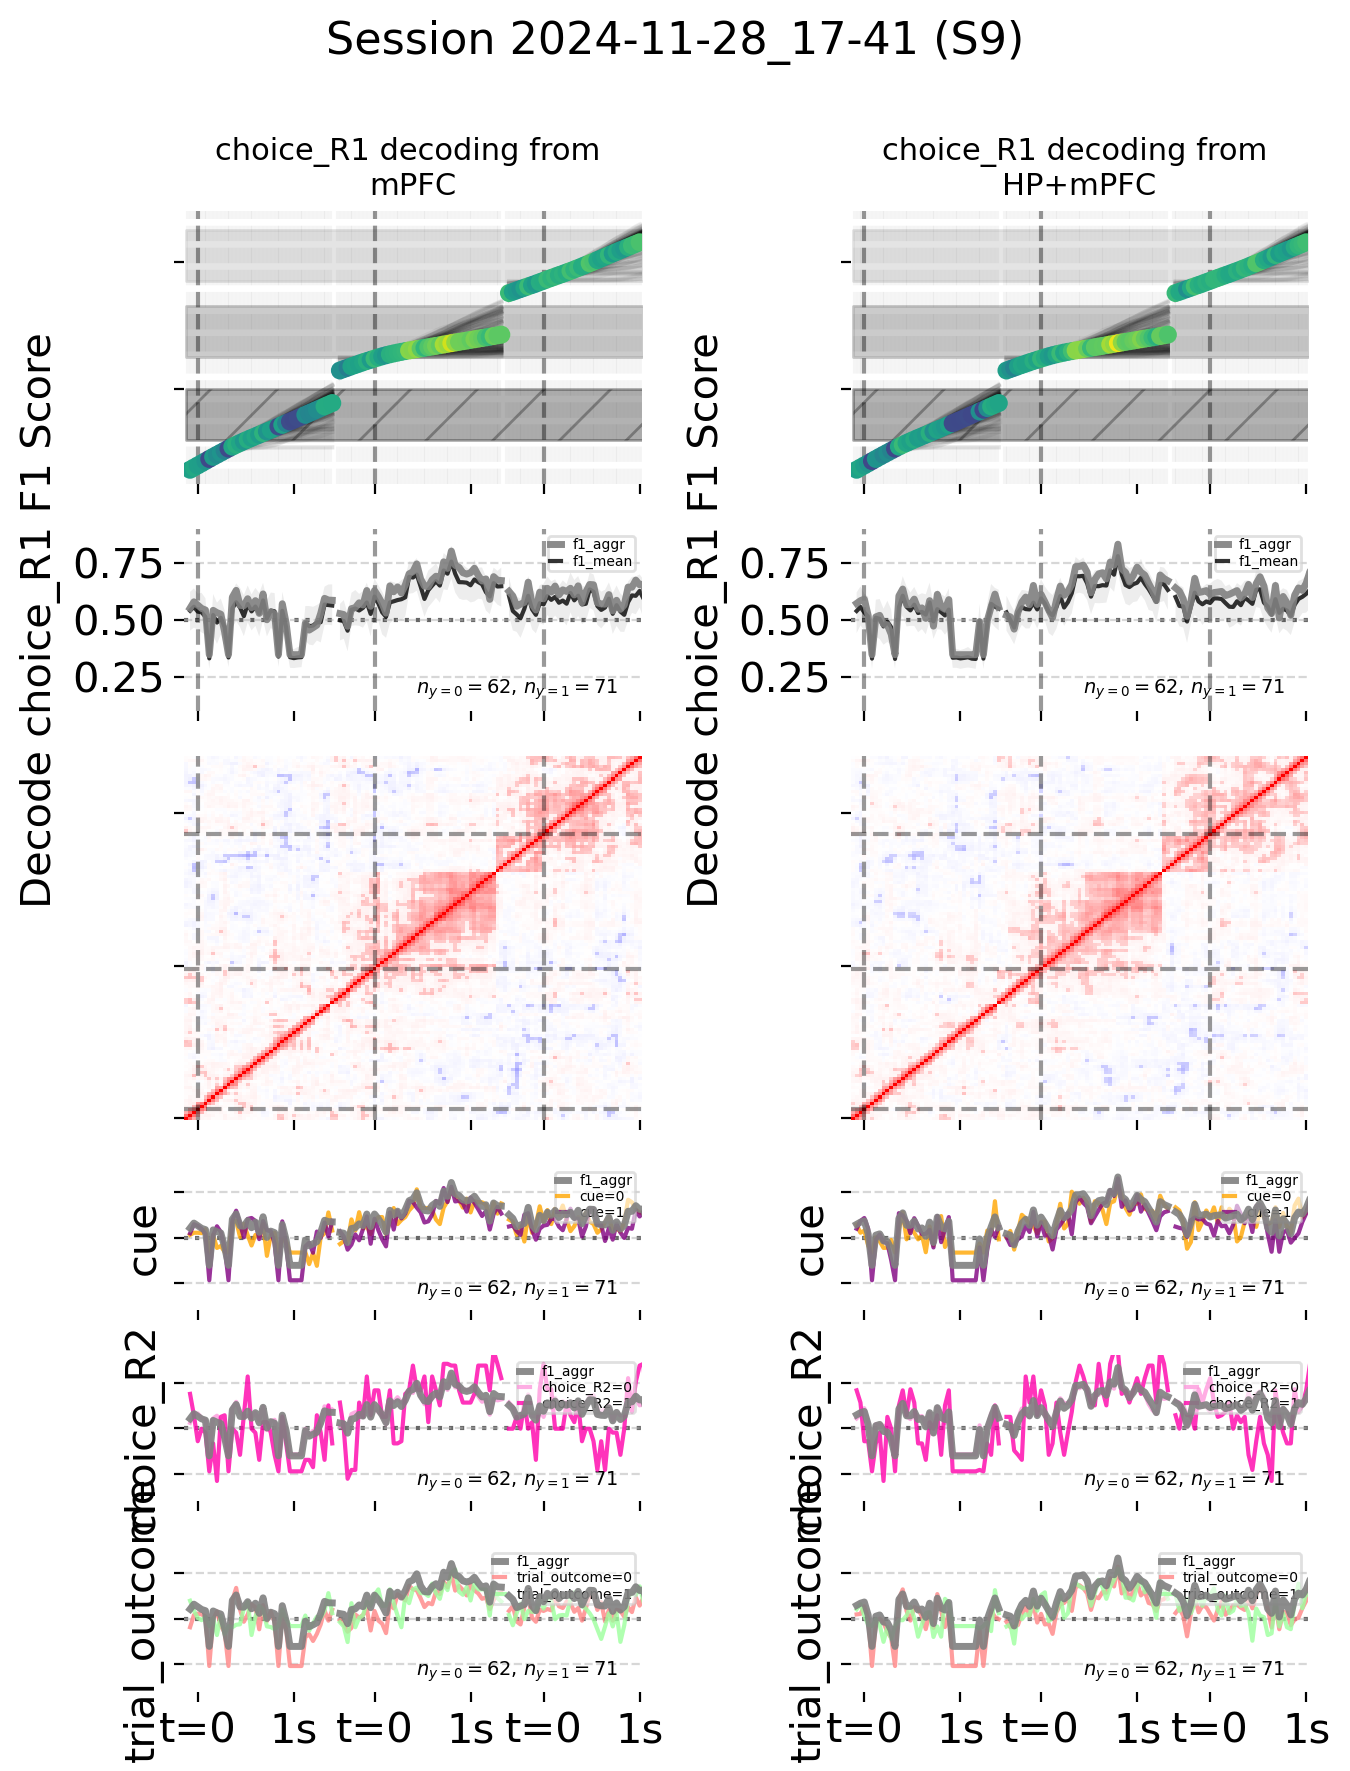

In [22]:
# POSTER PLOTS
#
# Per-session SVM decoding plot. Layout per column: (0) single-trial position
# trajectories colored by decode F1, (1) F1 over time (f1_aggr = bold reference
# over all trials, f1_mean = thin, mean across bootstrap iterations), (2) cosine-angle
# heatmap between per-timebin SVM weight vectors, (3+, optional) one small panel per
# other behavioral covariate (cue / choice_R1 / choice_R2 / trial_outcome), each
# showing F1 split by that covariate's value against the same f1_aggr baseline.
#
# Pass a list for x_modalities and/or y_predicted_names to plot_session_analysis to
# get one column per value; pass lists for *both* to multiplex every combination
# into its own column (see _resolve_column_specs).

from sklearn.metrics import f1_score


def _covariate_color(y_name, level):
    return modality_colors.get(y_name, {}).get(level, 'gray')


def _resolve_column_specs(x_modalities, y_predicted_names):
    """Build the (x_modality, y_predicted_name) pair for each output column.
    One of the two may be a single value (broadcast across the other's columns);
    if both are lists, every combination gets its own column (multiplexed)."""
    x_list = list(x_modalities) if isinstance(x_modalities, (list, tuple)) else [x_modalities]
    y_list = list(y_predicted_names) if isinstance(y_predicted_names, (list, tuple)) else [y_predicted_names]
    if len(x_list) > 1 and len(y_list) > 1:
        return [(xm, yp) for xm in x_list for yp in y_list]
    if len(x_list) == 1:
        x_list = x_list * len(y_list)
    if len(y_list) == 1:
        y_list = y_list * len(x_list)
    return list(zip(x_list, y_list))


def _stack_by_timebin(rows_df, column):
    """rows_df: one row per timebin for a single (interval, predict_y_name, X_modality).
    Returns an (n_trials, n_timebins) array, sorted by timebin."""
    rows_df = rows_df.sort_values('timebin')
    return np.stack(rows_df[column].values).T


def get_session_data(s_id, t0_events, behavior, svm_results, x_modality, y_predicted_name, which_intervals):
    """All data needed to plot one (session, x_modality, y_predicted_name) column."""
    target_svm_results = svm_results.loc[
        (svm_results.index.get_level_values('session_id') == s_id) &
        (svm_results['X_modality'] == x_modality) &
        (svm_results['predict_y_name'] == y_predicted_name) &
        (svm_results['interval_name'].isin(which_intervals))
    ]

    # Same slice, but *not* filtered to y_predicted_name. For a fixed (interval_name,
    # timebin, X_modality), every predict_y_name was fit on the exact same
    # svm_setup_dat (see timeline_decoding in postproc_mea1k_ephys.py: svm_setup_dat is
    # built once per interval_col_name, before the y_name loop) - so these sibling rows'
    # y_true is trial-order-aligned with target_svm_results' pred/y_true for the same
    # timebin. This is what lets plot_covariate_f1 condition on other covariates
    # without joining back to the behavior table.
    interval_svm_results = svm_results.loc[
        (svm_results.index.get_level_values('session_id') == s_id) &
        (svm_results['X_modality'] == x_modality) &
        (svm_results['interval_name'].isin(which_intervals))
    ]

    all_pos = {}
    print(f"\nGetting position trajectories for session {s_id}")
    for which_interval in which_intervals:
        trial_poss = []
        for trial_id, full_intrvl in t0_events.loc[s_id, which_interval].dropna().items():
            trial_behavior = behavior.xs(s_id, level='session_id')
            trial_behavior = trial_behavior[trial_behavior['trial_id'] == trial_id]
            dat = trial_behavior.loc[trial_behavior.index.overlaps(full_intrvl)]
            trial_poss.append(dat.frame_position.values)

        # keep only trials with the modal (most common) trajectory length
        lengths = pd.Series([len(x) for x in trial_poss])
        correct_length = lengths.value_counts().index[0]
        trial_pos = [pos for pos in trial_poss if len(pos) == correct_length]
        all_pos[which_interval] = np.stack(trial_pos)
        print(f"  {which_interval}: {len(trial_pos)}/{len(trial_poss)} trials at length {correct_length}")

    all_times = dat.index.mid.values - dat.index.mid[0]
    return target_svm_results, interval_svm_results, all_pos, all_times


def _resample_pos(pos_1d, n_bins):
    """Resample a 1D position array to n_bins using linear interpolation."""
    if len(pos_1d) == n_bins:
        return pos_1d
    return np.interp(np.linspace(0, 1, n_bins), np.linspace(0, 1, len(pos_1d)), pos_1d)


def _plot_f1_lines(ax, svm_res_target, which_intervals, ylabel, extra_lines=None, show_ci=False, show_n=True):
    """Shared F1-vs-time drawing routine, used by both the main F1 panel (row 1) and
    each per-covariate panel below it. Always draws the target's f1_aggr as a bold,
    high-contrast reference line on top of everything else; `extra_lines(which_interval,
    target_rows) -> [(values, color, label, linestyle), ...]` supplies whatever else
    should be compared against it for that interval (e.g. f1_mean, or a covariate's
    per-level F1). Concatenates intervals left-to-right with the shared offset scheme
    used everywhere in this notebook (offset advances by each interval's timebin count).
    Returns the final offset."""
    offset = 0
    n_pos = n_neg = None
    for which_interval in which_intervals:
        target_rows = svm_res_target[svm_res_target.interval_name == which_interval].sort_values('timebin')
        if target_rows.empty:
            continue
        timebins = target_rows.timebin.values
        first = offset == 0  # first interval actually drawn - only label it once

        ax.plot(timebins + offset, target_rows.f1_aggr.values, color='gray', linewidth=2.5,
                alpha=0.9, zorder=10, label='f1_aggr' if first else None)
        if show_ci:
            ax.fill_between(timebins + offset, target_rows.f1_ci_lower, target_rows.f1_ci_upper,
                             color='black', alpha=0.07, edgecolor=None, zorder=1)

        for values, color, label, ls in (extra_lines(which_interval, target_rows) if extra_lines else []):
            ax.plot(timebins + offset, values, color=color, linestyle=ls, alpha=0.8, zorder=5,
                    label=label if first else None)

        if n_pos is None:
            n_pos = target_rows.n_positives.values[0]
            n_neg = target_rows.n_negatives.values[0]
        offset += timebins.max() + 1

    ax.axhline(0.5, color='black', linestyle=':', alpha=0.6, zorder=1)
    ax.set_ylabel(ylabel)
    ax.set_ylim(.1, .9)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
    if show_n and n_pos is not None:
        ax.text(0.95, 0.05, f"$n_{{y=0}}={n_neg}$, $n_{{y=1}}={n_pos}$", transform=ax.transAxes,
                fontsize=7, verticalalignment='bottom', horizontalalignment='right')
    ax.legend(fontsize=5, loc='upper right', framealpha=0.6, handlelength=0.8,
              borderpad=0.15, labelspacing=0.15)
    return offset


def create_subplot(axes, all_pos, svm_res, title, y_predicted_name, which_intervals):
    """Row 0: trajectories colored by decode F1. Row 1: F1 over time (via _plot_f1_lines)."""
    offset = 0
    xticks = []
    for which_interval in which_intervals:
        this_interval_pos = all_pos[which_interval]
        # sort_values: rows must be timebin-ascending for the offset x-axis below,
        # and to align row-for-row with sibling predict_y_name rows in plot_covariate_f1
        svm_res_interval = svm_res[svm_res.interval_name == which_interval].sort_values('timebin')
        n_bins = len(svm_res_interval.timebin)

        for pos in this_interval_pos:
            pos_inner = _resample_pos(pos[1:-1], n_bins)
            axes[0].plot(svm_res_interval.timebin + offset, pos_inner, alpha=0.05, color='k', zorder=4)

        # Plot bin boundaries
        for t in svm_res_interval.timebin:
            axes[0].axvline(x=t-.5 + offset, color='k', linestyle='--', alpha=0.04)

        x_0 = 3+ offset if which_interval == 'cue_entry_interval' else 10+ offset
        xticks.extend([x_0, x_0+25])
        axes[0].axvline(x=x_0, color='k', linestyle='--', alpha=0.4)
        axes[1].axvline(x=x_0, color='k', linestyle='--', alpha=0.4)
        axes[2].axvline(x=x_0, color='k', linestyle='--', alpha=0.4)
        axes[2].axhline(y=x_0, color='k', linestyle='--', alpha=0.4)

        mean_pos = _resample_pos(this_interval_pos.mean(axis=0)[1:-1], n_bins)
        scatter = axes[0].scatter(svm_res_interval.timebin + offset, mean_pos,
                            c=svm_res_interval.f1_mean.values,
                            cmap=plt.cm.viridis,
                            norm=Normalize(vmin=0.2, vmax=0.8),
                            alpha=1,
                            s=30,
                            zorder=5)

        offset += svm_res_interval.timebin.max() +1

    _plot_f1_lines(
        axes[1], svm_res, which_intervals,
        ylabel=f'Decode {y_predicted_name} F1 Score',
        extra_lines=lambda which_interval, rows: [(rows.f1_mean.values, 'black', 'f1_mean', '-')],
        show_ci=True,
    )

    # rectangle for cue/R1/R2 zones
    axes[0].fill_betweenx(y=[-80, 0], x1=0, x2=offset, color='black', hatch='/', alpha=0.3, label='Cue Zone')
    axes[0].fill_betweenx(y=[50, 130], x1=0, x2=offset, color='darkgray', alpha=0.6, label='R1 Zone')
    axes[0].fill_betweenx(y=[170, 250], x1=0, x2=offset, color='lightgray', alpha=0.6, label='R2 Zone')

    axes[0].set_title(title, fontsize=11)
    axes[0].tick_params(labelleft=False, labelbottom=False)

    return scatter, xticks


def plot_covariate_f1_single(ax, interval_svm_results, y_predicted_name, covariate, which_intervals):
    """One small panel: the target's f1_aggr baseline vs. F1 recomputed separately for
    each level of `covariate` (a sibling predict_y_name fit on the same trials - see
    get_session_data for why this alignment is safe without a trial_id join). A big gap
    between the two lines means decoding y_predicted_name is confounded with covariate
    rather than generalizing across it - this generalizes the old hardcoded cue-R1
    split to run systematically over every other fitted label."""
    svm_res_target = interval_svm_results[interval_svm_results.predict_y_name == y_predicted_name]

    def extra_lines(which_interval, target_rows):
        cov_rows = interval_svm_results[(interval_svm_results.interval_name == which_interval) &
                                         (interval_svm_results.predict_y_name == covariate)]
        if cov_rows.empty:
            return []
        timebins = target_rows.timebin.values
        cov_rows = cov_rows[cov_rows.timebin.isin(timebins)].sort_values('timebin')
        pred = _stack_by_timebin(target_rows, 'predictions')
        true_y = _stack_by_timebin(target_rows, 'y_true')
        cov_true = _stack_by_timebin(cov_rows, 'y_true')
        if cov_true.shape[0] != true_y.shape[0]:
            print(f"plot_covariate_f1: skipping {covariate} in {which_interval}, "
                  f"trial count mismatch ({cov_true.shape[0]} vs {true_y.shape[0]})")
            return []

        lines = []
        for level in (0, 1):
            f1s = []
            for t_i in range(len(timebins)):
                mask = cov_true[:, t_i] == level
                if mask.sum() < 2 or len(np.unique(true_y[mask, t_i])) < 2:
                    f1s.append(np.nan)
                    continue
                f1s.append(f1_score(true_y[mask, t_i], pred[mask, t_i], average='macro'))
            lines.append((f1s, _covariate_color(covariate, level), f'{covariate}={level}', '-'))
        return lines

    _plot_f1_lines(ax, svm_res_target, which_intervals, ylabel=covariate, extra_lines=extra_lines)
    ax.tick_params(labelleft=False)
    [sp.set_visible(False) for sp in ax.spines.values()]


def plot_covariate_f1(axes, interval_svm_results, y_predicted_name, which_intervals, covariate_names=None):
    """One small subplot per covariate - axes is a sequence of Axes, one per entry in
    covariate_names (defaults to every fitted label except y_predicted_name itself).
    See plot_covariate_f1_single for what each panel shows."""
    if covariate_names is None:
        covariate_names = [y for y in ALL_Y_PREDICTED_NAMES if y != y_predicted_name]
    for ax, covariate in zip(axes, covariate_names):
        plot_covariate_f1_single(ax, interval_svm_results, y_predicted_name, covariate, which_intervals)


def plot_session_analysis(s_id, t0_events, behavior, svm_results, x_modalities, y_predicted_names,
                           which_intervals, show_covariate_plot=True, show_colorbar=False, covariate_names=None):
    """Plot the full per-session analysis. One column per (x_modality, y_predicted_name)
    pair - see _resolve_column_specs for how list(s) of either map to columns. With
    show_covariate_plot, one small extra row is added per covariate (see
    plot_covariate_f1)."""
    column_specs = _resolve_column_specs(x_modalities, y_predicted_names)
    ncols = len(column_specs)

    if show_covariate_plot and covariate_names is None:
        # same set for every column: total fitted labels minus whichever is the target
        # (constant count regardless of which target, since ALL_Y_PREDICTED_NAMES is fixed)
        n_covariates = len(ALL_Y_PREDICTED_NAMES) - 1
    else:
        n_covariates = len(covariate_names) if show_covariate_plot else 0

    nrows = 3 + n_covariates
    height_ratios = [1.5, 1, 2] + [0.8] * n_covariates
    fig_height = 1.3 * sum(height_ratios)

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(3.5 * ncols, fig_height),
                             height_ratios=height_ratios, sharex=True, dpi=200)
    if ncols == 1:
        axes = axes.reshape(nrows, 1)
    plt.subplots_adjust(hspace=0.15, wspace=0.05)

    scatter = im = None
    for col_i, (x_modality, y_predicted_name) in enumerate(column_specs):
        svm_res, interval_svm_results, all_pos, all_times = get_session_data(
            s_id, t0_events, behavior, svm_results, x_modality, y_predicted_name, which_intervals)

        scatter, xticks = create_subplot(axes[:3, col_i], all_pos, svm_res,
                                          f'{y_predicted_name} decoding from \n{x_modality}',
                                          y_predicted_name, which_intervals)
        if show_covariate_plot:
            plot_covariate_f1(axes[3:, col_i], interval_svm_results, y_predicted_name,
                               which_intervals, covariate_names)

        # Get the timebin values for x-axis alignment
        timebins = np.arange(len(svm_res))
        # Plot heatmap with aligned x-axis
        Ws = np.array(svm_res.w.to_list())
        cos_sim_matrix = np.dot(Ws, Ws.T) / (np.linalg.norm(Ws, axis=1)[:, np.newaxis] * np.linalg.norm(Ws, axis=1)[np.newaxis, :])
        cos_sim_matrix = np.arccos(np.clip(cos_sim_matrix, -1.0, 1.0)) * (180/np.pi)

        high_angles_alpha = ((cos_sim_matrix > angle_2std_thr[x_modality][1]) | (cos_sim_matrix < angle_2std_thr[x_modality][0])).astype(float)
        high_angles_alpha[high_angles_alpha==False] = .3

        # Use pcolormesh instead of imshow for better alignment
        X, Y = np.meshgrid(timebins, timebins)
        im = axes[2,col_i].pcolormesh(X, Y, cos_sim_matrix,
                                  alpha=high_angles_alpha,
                                 cmap='bwr_r', vmin=0, vmax=180)

        axes[2,col_i].set_xticks(xticks)
        axes[2,col_i].set_xticklabels(['t=0' if k%2==0 else '1s' for k in range(len(xticks))])
        axes[2,col_i].set_xlim(-0.5, len(timebins)-0.5)
        axes[2,col_i].set_ylim(-0.5, len(timebins)-0.5)
        axes[2,col_i].tick_params(labelleft=False)

        # turn off all spines
        for row_i in range(3):
            [sp.set_visible(False) for sp in axes[row_i, col_i].spines.values()]

    if show_colorbar and scatter is not None:
        cbar = plt.colorbar(scatter, ax=axes[0, -1])
        cbar.set_ticks([.75, .5, .25])
        cbar.set_label('SVM F1 Score', labelpad=15)

        cbar2 = plt.colorbar(im, ax=axes[2, -1])
        cbar2.set_ticks([0, 60, 90, 120, 180])
        cbar2.set_label('Angle between SVM planes (degrees)', labelpad=15)

    plt.suptitle(f'Session {s_id} (S{ith_to_dt_session.get(s_id, "Unknown")})', fontsize=16, y = .99, )
    plt.tight_layout()
    plt.show()

    # fname = os.path.join(output_dir, f'session_S{s_id}_{y_predicted_name}_svm_analysis_S15_Rest.svg')
    # fig.savefig(fname, dpi=300)



plt.close("all")
y_predicted_names = ['choice_R1']  # pick from ALL_Y_PREDICTED_NAMES; pass a list to add columns
x_modalities = ALL_X_MODALITIES  # combine with a list of y_predicted_names to multiplex combinations
which_intervals = ALL_INTERVALS

# Main execution
for s_id in svm_results.index.unique('session_id'):
    print(f"Plotting session {s_id}")
    # parse s_id as timestamp like  2024-11-14_16-40
    s_id_timestamp = pd.to_datetime(s_id, format='%Y-%m-%d_%H-%M')
    if not ((s_id_timestamp > to_s_id_07) and (s_id_timestamp < to_s_id_15)):
        continue

    plot_session_analysis(s_id, t0_events, behavior, svm_results,
                           x_modalities=x_modalities, y_predicted_names=y_predicted_names,
                           which_intervals=which_intervals)
    break
# First proper plot used in poster. Play around with the part above to select
# sessions, intervals, y_predicted_names, x_modalities.

In [ ]:
# Patch: make create_subplot robust to interval-length mismatches
def create_subplot(axes, all_pos, svm_res, trialwise_behavior, title, y_predicted_name, column_i):
    """Create a single subplot with trajectories and F1 score coloring."""
    offset = 0
    xticks = []
    title_suffix = ""
    
    for which_interval in which_intervals:
        this_interval_pos = all_pos[which_interval]
        svm_res_interval = svm_res[svm_res.interval_name == which_interval]
        
        if svm_res_interval.empty or this_interval_pos.size == 0:
            continue
        
        t = svm_res_interval.timebin.to_numpy()
        pos_mat = this_interval_pos
        
        # Prefer removing edge bins only when it matches SVM timeline; otherwise auto-align.
        if pos_mat.shape[1] >= 3 and (pos_mat.shape[1] - 2) == len(t):
            traj_mat = pos_mat[:, 1:-1]
        elif pos_mat.shape[1] == len(t):
            traj_mat = pos_mat
        else:
            n = min(len(t), pos_mat.shape[1])
            t = t[:n]
            traj_mat = pos_mat[:, :n]
        
        # Plot individual trajectories
        for pos in traj_mat:
            axes[0].plot(t + offset, pos, alpha=0.05, color='k', zorder=4)
        
        # Compute per-timebin F1 from per-trial predictions
        pred = svm_res_interval['predictions'].values
        pred = np.stack(pred).T
        pred = pred[:, :len(t)]
        
        true = trialwise_behavior.loc[:, y_predicted_name].values
        if y_predicted_name == 'cue':
            true = true - 1
        
        if x_modalities[0] == x_modalities[1]:
            if column_i == 0:
                choice_overlap_mask = ~trialwise_behavior['choice_R1'] == (trialwise_behavior['cue'] - 1)
                title_suffix = f'correct cue-R1 link trials n={choice_overlap_mask.sum()}'
            elif column_i == 1:
                choice_overlap_mask = ~trialwise_behavior['choice_R1'] != (trialwise_behavior['cue'] - 1)
                title_suffix = f'wrong cue-R1 link trials n={choice_overlap_mask.sum()}'
            else:
                choice_overlap_mask = np.ones(len(true), dtype=bool)
            true = true[choice_overlap_mask]
            pred = pred[choice_overlap_mask, :]
        
        from sklearn.metrics import f1_score
        f1_scores = []
        for timebin_i in range(pred.shape[1]):
            f1_scores.append(f1_score(true, pred[:, timebin_i], average='macro'))
        
        # Boundary lines
        for t_i in t:
            axes[0].axvline(x=t_i - 0.5 + offset, color='k', linestyle='--', alpha=0.04)
        
        x_0 = 3 + offset if which_interval == 'cue_entry_interval' else 10 + offset
        xticks.extend([x_0, x_0 + 25])
        axes[0].axvline(x=x_0, color='k', linestyle='--', alpha=0.4)
        axes[1].axvline(x=x_0, color='k', linestyle='--', alpha=0.4)
        axes[2].axvline(x=x_0, color='k', linestyle='--', alpha=0.4)
        axes[2].axhline(y=x_0, color='k', linestyle='--', alpha=0.4)
        
        axes[0].scatter(
            t + offset,
            traj_mat.mean(axis=0),
            c=f1_scores[:len(t)],
            cmap=plt.cm.viridis,
            norm=Normalize(vmin=0.2, vmax=0.8),
            alpha=1,
            s=30,
            zorder=5
        )
        
        # Performance curves (trimmed to aligned length)
        n_plot = len(t)
        f1_aggr = svm_res_interval.f1_aggr.values[:n_plot]
        f1_ci_lower = svm_res_interval.f1_ci_lower.values[:n_plot]
        f1_ci_upper = svm_res_interval.f1_ci_upper.values[:n_plot]
        
        axes[1].plot(t + offset, f1_aggr, color='black', alpha=0.3, zorder=5)
        axes[1].plot(t + offset, f1_scores[:n_plot], color='black', alpha=0.6, zorder=6)
        axes[1].fill_between(
            t + offset,
            f1_ci_lower,
            f1_ci_upper,
            color='black',
            alpha=0.07,
            edgecolor=None
        )
        
        offset += n_plot
    
    axes[1].axhline(0.5, color='black', linestyle=':', label='Chance Level')
    axes[1].set_ylabel(f'Decode {y_predicted_name} F1 Score')
    axes[1].yaxis.grid(True, linestyle='--', alpha=0.5)
    axes[1].set_ylim(0.1, 0.9)
    
    if len(svm_res) > 0:
        info_str = (
            f"$n_{{y=0}}={svm_res.n_negatives.values[0]}$, "
            f"$n_{{y=1}}={svm_res.n_positives.values[0]}$"
        )
        axes[1].text(
            0.95,
            0.75,
            info_str,
            transform=axes[1].transAxes,
            fontsize=10,
            verticalalignment='bottom',
            horizontalalignment='right'
        )
    
    axes[0].fill_betweenx(y=[-80, 0], x1=0, x2=offset, color='black', hatch='/', alpha=0.3, label='Cue Zone')
    axes[0].fill_betweenx(y=[50, 130], x1=0, x2=offset, color='darkgray', alpha=0.6, label='R1 Zone')
    axes[0].fill_betweenx(y=[170, 250], x1=0, x2=offset, color='lightgray', alpha=0.6, label='R2 Zone')
    
    axes[0].set_title(title + ('\n' + title_suffix if title_suffix else ''), fontsize=11)
    axes[0].tick_params(labelleft=False, labelbottom=False)
    return None, xticks

In [ ]:
# Quick smoke test on one session to confirm x/y length mismatch is gone
s_test = svm_results.index.unique('session_id')[0]
plot_session_analysis(s_test, t0_events, behavior, svm_results)

In [ ]:
# # POSTER PLOTS

# def get_session_data(s_id, t0_events, behavior, svm_results, x_modality):
#     """Get all relevant data for a single session and modality"""
#     # Get SVM results
#     X_modality_svm_results = svm_results.loc[
#         (svm_results.index.get_level_values('session_id') == s_id) & 
#         (svm_results['X_modality'] == x_modality) &
#         (svm_results['predict_y_name'] == y_predicted_name) &
#         (svm_results['interval_name'].isin(which_intervals))
#     ]
    
#     # Get behavior trajectories
#     all_pos = {}
#     print("\nGetting positions data for session:", s_id)
#     for which_interval in which_intervals:
#         print("Interval ", which_interval)
#         # all_pos[which_interval] = []
#         trial_poss = []
#         for trial_id, full_intrvl in t0_events.loc[s_id, which_interval].dropna().items():

#             trial_behavior = behavior.xs(s_id, level='session_id')
#             trial_behavior = trial_behavior[trial_behavior['trial_id'] == trial_id]
#             dat = trial_behavior.loc[trial_behavior.index.overlaps(full_intrvl)]
#             print(dat.shape, end="; ")
#             trial_poss.append(dat.frame_position.values)

#         # Filter trials with wrong length
#         lengths = pd.Series([len(x) for x in trial_poss])
#         correct_length = lengths.value_counts().index[0]
#         print(f"\n{correct_length=}")
#         trial_pos = [pos for pos in trial_poss if len(pos) == correct_length]
#         all_pos[which_interval] = np.stack(trial_pos)
#         print("SVM data shape: ", X_modality_svm_results[X_modality_svm_results.interval_name == which_interval].shape)
#         print()
#     return X_modality_svm_results, all_pos, dat.index.mid.values - dat.index.mid[0]

# def create_subplot(axes, all_pos, svm_res, title, y_predicted_name):
#     """Create a single subplot with trajectories and F1 score coloring"""
    
#     # iter intervals
#     offset = 0
#     xticks = []
#     for which_interval in which_intervals:
#         # Plot individual trajectories
#         this_interval_pos = all_pos[which_interval]
#         svm_res_interval = svm_res[svm_res.interval_name == which_interval]

#         for pos in this_interval_pos:
#             axes[0].plot(svm_res_interval.timebin + offset, pos[1:-1], alpha=0.05, color='k', zorder=4)

#         # Plot bin boundaries
#         for t in svm_res_interval.timebin:
#             axes[0].axvline(x=t-.5 + offset, color='k', linestyle='--', alpha=0.04)

#         x_0 = 3+ offset if which_interval == 'cue_entry_interval' else 10+ offset
#         xticks.extend([x_0, x_0+25])
#         axes[0].axvline(x=x_0, color='k', linestyle='--', alpha=0.4)
#         axes[1].axvline(x=x_0, color='k', linestyle='--', alpha=0.4)
#         axes[2].axvline(x=x_0, color='k', linestyle='--', alpha=0.4)
#         axes[2].axhline(y=x_0, color='k', linestyle='--', alpha=0.4)
        
#         scatter = axes[0].scatter(svm_res_interval.timebin + offset, (this_interval_pos).mean(axis=0)[1:-1],
#                             c=svm_res_interval.f1_mean,
#                             cmap=plt.cm.viridis,
#                             norm=Normalize(vmin=0.2, vmax=0.8),
#                             alpha=1,
#                             s=30,
#                             zorder=5)
        
#         # plot performance over timepoints
#         axes[1].plot(svm_res_interval.timebin + offset, svm_res_interval.f1_mean, color='black', alpha=0.6, zorder=5)
#         # draw confidence intervals svm_res.f1_ci_lower, svm_res.f1_ci_upper
#         axes[1].fill_between(svm_res_interval.timebin + offset, svm_res_interval.f1_ci_lower, 
#                              svm_res_interval.f1_ci_upper, color='black', alpha=0.07,
#                              edgecolor=None)
        
#         # axes[2].axvline(svm_res_interval.timebin.max()+offset +.5, color='white', linewidth=3, alpha=1, zorder=5)
#         # axes[2].axhline(svm_res_interval.timebin.max()+offset +.5, color='white', linewidth=3, alpha=1, zorder=5)
#         offset += svm_res_interval.timebin.max() +1
    
#     axes[1].axhline(0.5, color='black', linestyle=':', label='Chance Level')
#     axes[1].set_ylabel(f'Decode {y_predicted_name} F1 Score')
#     # y grid
#     axes[1].yaxis.grid(True, linestyle='--', alpha=0.5)
#     axes[1].set_ylim(.1,.9)
#     info_str = (f"$n_{{y=0}}={svm_res_interval.n_negatives.values[0]}$, "
#                 f"$n_{{y=1}}={svm_res_interval.n_positives.values[0]}$")
#                 # f"n bootstr.: {svm_res_interval.n_iterations.values[0]} ") #, failed: {svm_res_interval.n_success_iterations.values[0]-svm_res_interval.n_iterations.values[0]}, ")
#     axes[1].text(0.95, 0.75, info_str, transform=axes[1].transAxes,
#         fontsize=10, verticalalignment='bottom', horizontalalignment='right')
        
        
            
#     # Add reference lines
#     # rectangle for cue zone
#     # axes[0].hlines(y=-120, xmin=0, xmax=offset, color='gray', linestyle='--', label='Cue Zone Visible')
#     axes[0].fill_betweenx(y=[-80, 0], x1=0, x2=offset, color='black', hatch='/', alpha=0.3, label='Cue Zone')
#     axes[0].fill_betweenx(y=[50, 130], x1=0, x2=offset, color='darkgray', alpha=0.6, label='R1 Zone')
#     axes[0].fill_betweenx(y=[170, 250], x1=0, x2=offset, color='lightgray', alpha=0.6, label='R2 Zone')

#     # Labels
#     # axes[0].legend()
#     axes[0].set_title(title)
#     axes[0].tick_params(labelleft=False, labelbottom=False)

#     return scatter, xticks

# def plot_session_analysis(s_id, t0_events, behavior, svm_results):
#     """Plot complete analysis for one session"""
#     fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(7, 6), height_ratios=[1.5, 1, 2], 
#                              sharex=True)
#     # reduce space between subplots
#     plt.subplots_adjust(hspace=0.01, wspace=0.01)
#     # y_predicted_name = svm_results['predict_y_name'].values[0] # all the same
#     # y_predicted_name = 'cue'
    
#     # Plot first row with existing analysis
#     for i, x_modality in enumerate(x_modalities):
#     # for i, x_modality in enumerate(['mPFC']):
#         svm_res, all_pos, all_times = get_session_data(s_id, t0_events, behavior, svm_results, x_modality)
#         # f1_scores = [np.nan, *svm_res.f1_mean.to_list(), np.nan]
#         scatter, xticks = create_subplot(axes[:,i], all_pos, svm_res, 
#                                  f'{y_predicted_name} decoding from \n{x_modality}', y_predicted_name)
        
        
#         # Get the timebin values for x-axis alignment
#         timebins = np.arange(len(svm_res))
#         # Plot heatmap with aligned x-axis
#         Ws = np.array(svm_res.w.to_list())
#         cos_sim_matrix = np.dot(Ws, Ws.T) / (np.linalg.norm(Ws, axis=1)[:, np.newaxis] * np.linalg.norm(Ws, axis=1)[np.newaxis, :])
#         cos_sim_matrix = np.arccos(np.clip(cos_sim_matrix, -1.0, 1.0)) * (180/np.pi)

#         high_angles_alpha = ((cos_sim_matrix > angle_2std_thr[x_modality][1]) | (cos_sim_matrix < angle_2std_thr[x_modality][0])).astype(float)
#         high_f1_mask = svm_res.f1_mean.values > .55
#         high_angles_alpha[high_angles_alpha==False] = .3
#         # high_angles_alpha[~high_f1_mask,:] = .3
#         # high_angles_alpha[:, ~high_f1_mask] = .3

#         # Use pcolormesh instead of imshow for better alignment
#         X, Y = np.meshgrid(timebins, timebins)
#         im = axes[2,i].pcolormesh(X, Y, cos_sim_matrix, 
#                                   alpha=high_angles_alpha,
#                                  cmap='bwr_r', vmin=0, vmax=180)
        
#         axes[2,i].set_xticks(xticks)
#         axes[2,i].set_xticklabels(['t=0' if i%2==0 else '1s' for i in range(len(xticks))])
    
#         # Set proper aspect ratio and limits
#         # axes[2,i].set_aspect('equal')
#         axes[2,i].set_xlim(-0.5, len(timebins)-0.5)
#         axes[2,i].set_ylim(-0.5, len(timebins)-0.5)
#         axes[2,i].tick_params(labelleft=False)
#         # turn off all spines
#         [sp.set_visible(False) for sp in axes[0,i].spines.values()]
#         [sp.set_visible(False) for sp in axes[1,i].spines.values()]
#         [sp.set_visible(False) for sp in axes[2,i].spines.values()]
        
        
#     # # Add colorbar
#     # cbar = plt.colorbar(scatter, ax=axes[1,-1])
#     # cbar.set_ticks([.75, .5, .25])
#     # cbar.set_label('SVM F1 Score', labelpad=15)
    
#     # # other colorbar
#     # cbar2 = plt.colorbar(im, ax=axes[-1,-1])
#     # cbar2.set_ticks([0, 60, 90, 120, 180])
#     # cbar2.set_label('Angle between SVM planes (degrees)', labelpad=15)

#     plt.suptitle(f'Session {s_id}', fontsize=16, y = .99, )
#     plt.tight_layout()
#     plt.show()

#     fname = os.path.join(output_dir, f'session_S{s_id}_{y_predicted_name}_svm_analysis_S15_Rest.svg')
#     fig.savefig(fname, dpi=300)
#     #degree sign
#     # 45 °


# plt.close("all")
# y_predicted_name = 'cue'
# # y_predicted_name = 'choice_R2'
# x_modalities = ['HP+mPFC', 'mPFC']
# which_intervals = ['cue_entry_interval', 'R1_entry_interval', 'R2_entry_interval']
# # which_intervals = ['cue_entry_interval', 'R2_entry_interval',]

# # Main execution
# for s_id in svm_results.index.unique('session_id'):
#     print(f"Plotting session {s_id}")

    # s_id_timestamp = pd.to_datetime(s_id, format='%Y-%m-%d_%H-%M')
    #     if not ((s_id_timestamp > to_s_id_07) and (s_id_timestamp < to_s_id_15)):
    #         continue
        
        
#     # if s_id in (24,25):
#     # if s_id not in (9,10,11,12,13,14):
#     #     # session with cropped SS, skip
#     if s_id not in (14,):
#         continue
        
#     plot_session_analysis(s_id, t0_events, behavior, svm_results)
#     # if s_id != 3:

#     # break
    
    
# # First proper plot using in poster. Play around with the part directly above
# # to select sessions, intervals, y_predicted_name, x_modalities

In [ ]:
# outlier plot: the overlap of different labels in session 14

trialw_behavior = analytics.get_analytics('BehaviorTrialwise', session_names=session_names[14:15])
trialw_behavior.index = trialw_behavior.index.droplevel(['entry_id', 'paradigm_id', 'animal_id'])
trialw_behavior.set_index("trial_id", append=True, inplace=True)
trialw_behavior.loc[:, 'trial_outcome'] = trialw_behavior.loc[:,'trial_outcome'].clip(0,1)

print(trialw_behavior.cue.value_counts())
print(trialw_behavior.choice_R1.value_counts())
print(trialw_behavior.trial_outcome.value_counts())

# Create visualization of label overlap
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
plt.subplots_adjust(hspace=0.05)  # Reduce space between plots

# Get data
cue_1_trials = trialw_behavior[trialw_behavior.cue == 1]
cue_2_trials = trialw_behavior[trialw_behavior.cue == 2]

# Top plot: Cue distribution (Orange for Cue 1, Purple for Cue 2)
cue_counts = [len(cue_1_trials), len(cue_2_trials)]
axes[0].barh([0], [cue_counts[0]], left=0, color='orange', label='Cue 1', height=0.6)
axes[0].barh([0], [cue_counts[1]], left=cue_counts[0], color='purple', label='Cue 2', height=0.6)
axes[0].set_ylim(-0.5, 0.5)
axes[0].set_xlim(0, sum(cue_counts))
axes[0].set_yticks([0])
axes[0].set_yticklabels(['Cue'])
# axes[0].legend(loc='upper right')
axes[0].set_title('Distribution of Labels Across Trials', fontsize=14, fontweight='bold')
axes[0].text(cue_counts[0]/2, 0, f'n={cue_counts[0]}', ha='center', va='center', fontsize=10, fontweight='bold')
axes[0].text(cue_counts[0] + cue_counts[1]/2, 0, f'n={cue_counts[1]}', ha='center', va='center', fontsize=10, fontweight='bold')

# Middle plot: Choice_R1 distribution split by cue (Dark gray for Stop R1, Gray for Skip R1)
cue1_choice_counts = [
    len(cue_1_trials[cue_1_trials.choice_R1 == False]),    # Skip R1
    len(cue_1_trials[cue_1_trials.choice_R1 == True])  # Stop R1
]
print(cue_1_trials)
print(cue1_choice_counts)
cue2_choice_counts = [
    len(cue_2_trials[cue_2_trials.choice_R1 == False]),    # Skip R1
    len(cue_2_trials[cue_2_trials.choice_R1 == True]),  # Stop R1
]

# Cue 1 side
axes[1].barh([0], [cue1_choice_counts[0]], left=0, color='#404040', label='Stop R1', height=0.6)
axes[1].barh([0], [cue1_choice_counts[1]], left=cue1_choice_counts[0], color='#808080', label='Skip R1', height=0.6)
# Cue 2 side
axes[1].barh([0], [cue2_choice_counts[0]], left=cue_counts[0], color='#404040', height=0.6)
axes[1].barh([0], [cue2_choice_counts[1]], left=cue_counts[0] + cue2_choice_counts[0], color='#808080', height=0.6)

axes[1].set_ylim(-0.5, 0.5)
axes[1].set_xlim(0, sum(cue_counts))
axes[1].set_yticks([0])
axes[1].set_yticklabels(['Choice R1'])
# axes[1].legend(loc='upper right')
axes[1].axvline(cue_counts[0], color='black', linestyle='--', alpha=0.3)

# Add counts
axes[1].text(cue1_choice_counts[0]/2, 0, f'{cue1_choice_counts[0]}', ha='center', va='center', fontsize=9, color='white', fontweight='bold')
axes[1].text(cue1_choice_counts[0] + cue1_choice_counts[1]/2, 0, f'{cue1_choice_counts[1]}', ha='center', va='center', fontsize=9, fontweight='bold')
axes[1].text(cue_counts[0] + cue2_choice_counts[0]/2, 0, f'{cue2_choice_counts[0]}', ha='center', va='center', fontsize=9, color='white', fontweight='bold')
axes[1].text(cue_counts[0] + cue2_choice_counts[0] + cue2_choice_counts[1]/2, 0, f'{cue2_choice_counts[1]}', ha='center', va='center', fontsize=9, fontweight='bold')

# Bottom plot: Trial outcome distribution split by cue (Red for no reward, Green for reward)
cue1_outcome_counts = [
    len(cue_1_trials[cue_1_trials.trial_outcome == 0]),  # No Reward
    len(cue_1_trials[cue_1_trials.trial_outcome == 1])   # Reward
]
cue2_outcome_counts = [
    len(cue_2_trials[cue_2_trials.trial_outcome == 0]),  # No Reward
    len(cue_2_trials[cue_2_trials.trial_outcome == 1])   # Reward
]

# Cue 1 side
axes[2].barh([0], [cue1_outcome_counts[0]], left=0, color='red', label='No Reward', height=0.6)
axes[2].barh([0], [cue1_outcome_counts[1]], left=cue1_outcome_counts[0], color='green', label='Reward', height=0.6)
# Cue 2 side
axes[2].barh([0], [cue2_outcome_counts[0]], left=cue_counts[0], color='red', height=0.6)
axes[2].barh([0], [cue2_outcome_counts[1]], left=cue_counts[0] + cue2_outcome_counts[0], color='green', height=0.6)

axes[2].set_ylim(-0.5, 0.5)
axes[2].set_xlim(0, sum(cue_counts))
axes[2].set_yticks([0])
axes[2].set_yticklabels(['Outcome'])
axes[2].legend(loc='upper right')
axes[2].axvline(cue_counts[0], color='black', linestyle='--', alpha=0.3)
axes[2].set_xlabel('Number of Trials', fontsize=12)

# Add counts
axes[2].text(cue1_outcome_counts[0]/2, 0, f'{cue1_outcome_counts[0]}', ha='center', va='center', fontsize=9, color='white', fontweight='bold')
axes[2].text(cue1_outcome_counts[0] + cue1_outcome_counts[1]/2, 0, f'{cue1_outcome_counts[1]}', ha='center', va='center', fontsize=9, fontweight='bold')
axes[2].text(cue_counts[0] + cue2_outcome_counts[0]/2, 0, f'{cue2_outcome_counts[0]}', ha='center', va='center', fontsize=9, color='white', fontweight='bold')
axes[2].text(cue_counts[0] + cue2_outcome_counts[0] + cue2_outcome_counts[1]/2, 0, f'{cue2_outcome_counts[1]}', ha='center', va='center', fontsize=9, fontweight='bold')


plt.tight_layout()
plt.show()
fname = os.path.join(output_dir, f'trial_label_distribution.svg')
fig.savefig(fname, dpi=300)

In [ ]:
# plot for showing that decoding performance goes up over sessions


# y_predicted_name = 'cue'
y_predicted_name = 'choice_R1'
which_intervals = ['cue_entry_interval', 'R1_entry_interval',]
x_modal = 'mPFC'
fname = f'avg_f1_vs_session_{y_predicted_name}_{x_modal}.svg'
# s_ids = [9,10,11,12,13,14]
# s_ids = [6,7,9,10,11,12,13,14]
s_ids = []

avg_f1 = []
for i, s_id in enumerate(svm_results.index.unique('session_id')):
    
    s_id_timestamp = pd.to_datetime(s_id, format='%Y-%m-%d_%H-%M')
    # if (s_id_timestamp < to_s_id_07):
    # if not ((s_id_timestamp > to_s_id_07) and (s_id_timestamp < to_s_id_15)):
    #     continue
    s_ids.append(s_id.replace('2024-', '').replace('2025-', ''))
    
    # if s_id not in s_ids:
    #     continue
    s_svm_results = svm_results.xs(s_id, level='session_id')
    s_svm_results = s_svm_results[(s_svm_results['predict_y_name'] == y_predicted_name) &
                              (s_svm_results['X_modality'] == x_modal) &
                              (s_svm_results['interval_name'].isin(which_intervals))]
    avg_f1.append((i, s_svm_results.f1_mean.mean()))

avg_f1 = np.array(avg_f1)
print(avg_f1, avg_f1.shape)

plt.figure(figsize=(4,3))
# Color points by F1 score using viridis colormap scaled from 0.2 to 0.8
scatter = plt.scatter(avg_f1[:,0], avg_f1[:,1], 
                     c=avg_f1[:,1],
                     cmap='viridis',
                     norm=Normalize(vmin=0.2, vmax=0.8),
                     s=100,
                     edgecolors='black',
                     linewidths=0.5)

# Linear fit
m, b = np.polyfit(avg_f1[:,0], avg_f1[:,1], 1)
plt.plot(avg_f1[:,0], m*avg_f1[:,0] + b, color='gray', linestyle='--', linewidth=2)
plt.title(y_predicted_name)

# Correlation
corr, pval = stats.pearsonr(avg_f1[:,0], avg_f1[:,1])
plt.text(0.95, 0.1, f'r={corr:.2f}\np={pval:.3f} *', transform=plt.gca().transAxes,
         verticalalignment='bottom', horizontalalignment='right')

plt.xlabel('Session ID')
plt.ylabel('Average F1 Score')
plt.ylim(.2,.8)
plt.yticks([.25, .5, .6, .75])
plt.gca().yaxis.grid(True, linestyle='--', alpha=0.5)

plt.xticks(range(len(s_ids)))
plt.gca().set_xticklabels(s_ids, rotation=45, ha='right')
# plt.xlim(min(s_ids)-.5, max(s_ids)+.5)

plt.xlabel('Session')
plt.axhline(.5, color='black', linestyle=':')
# no spines except left
[sp.set_visible(False) for sp in plt.gca().spines.values() if sp != plt.gca().spines['left']]

# # Add colorbar
# cbar = plt.colorbar(scatter)
# cbar.set_ticks([0.25, 0.5, 0.75])
# cbar.set_label('F1 Score', labelpad=15)

plt.tight_layout()
plt.show()

plt.savefig(os.path.join(output_dir, fname), dpi=300)

In [ ]:
svm_res

In [ ]:
# angles between SVM planes across sessions for the same y_prediction

from scipy.ndimage import gaussian_filter

plt.close("all")
y_predicted_name = 'choice_R1'
which_intervals = ['cue_entry_interval', 'R1_entry_interval',]
# which_intervals = ['R1_entry_interval', 'R2_entry_interval',]
# session_subset = [6,7,9,10,11,12,13,14]

for x_modal in ['mPFC', 'HP+mPFC']:
    plt.figure(figsize=(20,20))
    svm_res = svm_results[(svm_results['X_modality'] == x_modal) &
                          (svm_results['predict_y_name'] == y_predicted_name) &
                          (svm_results['interval_name'].isin(which_intervals))
                          ].set_index('timebin', append=True)
    svm_res.index = svm_res.index.droplevel(("paradigm_id", "animal_id", "entry_id"))
    
    # svm_res = svm_res.loc[svm_res.index.get_level_values('session_id').isin(session_subset)]
    # Filter out session-timebins based on s_id_timestamp
    # Assuming svm_res has a 's_id_timestamp' column
    
    # for i, s_id in enumerate(svm_results.index.unique('session_id')):
    
    # s_id_timestamp = pd.to_datetime(s_id, format='%Y-%m-%d_%H-%M')
    # # if (s_id_timestamp < to_s_id_07):
    # # if not ((s_id_timestamp > to_s_id_07) and (s_id_timestamp < to_s_id_15)):
    # #     continue
    # s_ids.append(s_id.replace('2024-', '').replace('2025-', ''))
    
    
    s_id_timestamp = svm_res.index.get_level_values('session_id').to_series().apply(lambda s_id: pd.to_datetime(s_id, format='%Y-%m-%d_%H-%M'))
    mask = (s_id_timestamp > to_s_id_07) & (s_id_timestamp < to_s_id_15)
    svm_res = svm_res[mask.values]
    
    # print(s_id_timestamp)
    # if s_id_timestamp is not None:
    #     if not mask.any():
    #         continue


    Ws = np.array(svm_res.w.to_list())
    cos_sim_matrix = np.dot(Ws, Ws.T) / (np.linalg.norm(Ws, axis=1)[:, np.newaxis] * np.linalg.norm(Ws, axis=1)[np.newaxis, :])
    cos_sim_matrix = np.arccos(np.clip(cos_sim_matrix, -1.0, 1.0)) * (180/np.pi)

    # Apply Gaussian blur
    cos_sim_matrix_blurred = gaussian_filter(cos_sim_matrix, sigma=0)

    high_angles_alpha = ((cos_sim_matrix_blurred > angle_2std_thr[x_modal][1]) | 
                         (cos_sim_matrix_blurred < angle_2std_thr[x_modal][0])).astype(float)
    high_f1 = svm_res.f1_mean.values > .55
    high_angles_alpha[~high_f1,:] = .3
    high_angles_alpha[:, ~high_f1] = .3
    high_angles_alpha[high_angles_alpha==False] = .3

    # Use pcolormesh instead of imshow for better alignment
    X, Y = np.meshgrid(np.arange(cos_sim_matrix.shape[1]), np.arange(cos_sim_matrix.shape[0]))
    im = plt.pcolormesh(X, Y, cos_sim_matrix_blurred, 
                                alpha=high_angles_alpha,
                                cmap='bwr_r', vmin=0, vmax=180)
    
    plt.colorbar(im, label='Angle (degrees)')
    plt.title(f'Cosine Similarity of SVM Weights - {x_modal} - {y_predicted_name}')
    plt.xlabel('Session-Timebin Index') 
    plt.ylabel('Session-Timebin Index')
    
    # # draw every session-timebin tick where timebin == 20 (middle of cue visible period)
    # ticks = [t if t[1] == 20 else None for t in svm_res.index]
    # new_s_ids = np.diff(svm_res.index.get_level_values('session_id')) != 0
    # new_s_ids = np.insert(new_s_ids, 0, True)
    # new_s_ids = np.arange(len(svm_res))[new_s_ids]
    
    ticks = [t if t[1] == 20 else None for t in svm_res.index]
    # Fix: convert session_id to numeric for diff
    session_ids = svm_res.index.get_level_values('session_id')
    try:
        session_ids_numeric = pd.to_numeric(session_ids)
    except Exception:
        # fallback: try to extract numbers from string like '2024-11-14_16-40'
        session_ids_numeric = pd.factorize(session_ids)[0]
    new_s_ids = np.diff(session_ids_numeric) != 0
    new_s_ids = np.insert(new_s_ids, 0, True)
    new_s_ids = np.arange(len(svm_res))[new_s_ids]
    
    
    
    # draw axh and v lines
    for t in range(len(svm_res)):
        if ticks[t] is not None:
            plt.axhline(y=t-20, color='black', linestyle='--', linewidth=.5, alpha=0.1)
            plt.axvline(x=t-20, color='black', linestyle='--', linewidth=.5, alpha=0.1)
    all_lbls = []
    for ns in new_s_ids:
        lw = 2 if svm_res.index[ns][0] in (20,26) else 0.5
        plt.axhline(y=ns-0.5, color='gray', linestyle='-', linewidth=lw, alpha=0.2)
        plt.axvline(x=ns-0.5, color='gray', linestyle='-', linewidth=lw, alpha=0.2)
        lbl = f"S{svm_res.index[ns][0]}"
        plt.text(ns, -5, lbl, 
                 verticalalignment='bottom', horizontalalignment='left', fontsize=6)
        plt.text(-5, ns+5, lbl,
                 verticalalignment='top', horizontalalignment='right', fontsize=6)
        all_lbls.append(lbl)
        
    plt.yticks(new_s_ids, all_lbls)
    plt.xticks(new_s_ids, all_lbls)
    plt.tick_params(axis='both', which='both', labelleft=False, labelright=True, right=True)
    plt.tight_layout()
    plt.show()
    
    # save figure
    fname = os.path.join(output_dir, f'cosine_similarity_{y_predicted_name}_{x_modal}_blurred.png')
    plt.savefig(fname, dpi=300)
    # break
    
    plt.figure(figsize=(6,6))
    print(f"shape: {cos_sim_matrix.shape}")
    high_f1_data = cos_sim_matrix[high_f1][:, high_f1].flatten()
    print(f"n high F1: {len(high_f1_data)}")
    low_f1_data = cos_sim_matrix[~high_f1][:, ~high_f1].flatten()
    print(f"n low F1: {len(low_f1_data)}")
    
    plt.hist(high_f1_data[high_f1_data>2], bins=50, color='green', edgecolor='black', alpha=0.5 , density=True)
    plt.hist(low_f1_data[low_f1_data>2], bins=50, color='gray', edgecolor='black', alpha=0.5   , density=True)
    # t test
    t_stat, p_val = stats.ttest_ind(high_f1_data, low_f1_data, equal_var=False)
    plt.text(0.95, 0.95, f't={t_stat:.2f}\np={p_val:.3e}', transform=plt.gca().transAxes,
                verticalalignment='top', horizontalalignment='right')
    plt.title(f'high F1 - Cosine Similarity Angles - {x_modal} - {y_predicted_name}')
    plt.xlabel('Angle (degrees)')
    plt.ylabel('Count')
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
# nasty gpt slop: THis is the panel 8, copmaring angles between predicters and sessions:

from scipy.ndimage import gaussian_filter
from scipy import stats

plt.close("all")
y_predicted_names = ['cue', 'choice_R1']
which_intervals = ['cue_entry_interval', 'R1_entry_interval']
session_subset = [9, 11, 12, 13, 14]
thr = .55

low_f1_col = '#445e8aff'
high_f1_col = '#9bd15aff'

def plot_cross_predictor_comparison(x_modal, y_predicted_names, which_intervals, session_subset, thr, svm_results):
    """Plot cross-predictor comparison for a single brain region"""
    # Create figure with 6 columns and 2 rows
    fig, axes = plt.subplots(figsize=(15, 8), ncols=6, nrows=2, 
                            gridspec_kw={'height_ratios': [6, 1.5]})
    
    # Get SVM results
    svm_res = svm_results[(svm_results['X_modality'] == x_modal) &
                          (svm_results['predict_y_name'].isin(y_predicted_names)) &
                          (svm_results['interval_name'].isin(which_intervals))
                          ].set_index('timebin', append=True)
    svm_res.index = svm_res.index.droplevel(("paradigm_id", "animal_id", "entry_id"))
    svm_res = svm_res.loc[svm_res.index.get_level_values('session_id').isin(session_subset)]

    # Initialize arrays for storing results
    cue_high_f1_angles = np.zeros((len(session_subset), len(session_subset)))
    cue_low_f1_angles = np.zeros((len(session_subset), len(session_subset)))
    choice_high_f1_angles = np.zeros((len(session_subset), len(session_subset)))
    choice_low_f1_angles = np.zeros((len(session_subset), len(session_subset)))
    cross_predictor_high_f1_angles = np.zeros((len(session_subset), len(session_subset)))
    cross_predictor_low_f1_angles = np.zeros((len(session_subset), len(session_subset)))
    
    # Also store std for error bars
    cue_high_f1_angles_std = np.zeros((len(session_subset), len(session_subset)))
    cue_low_f1_angles_std = np.zeros((len(session_subset), len(session_subset)))
    choice_high_f1_angles_std = np.zeros((len(session_subset), len(session_subset)))
    choice_low_f1_angles_std = np.zeros((len(session_subset), len(session_subset)))
    cross_predictor_high_f1_angles_std = np.zeros((len(session_subset), len(session_subset)))
    cross_predictor_low_f1_angles_std = np.zeros((len(session_subset), len(session_subset)))
    
    # Store raw angle distributions for statistical testing
    cue_high_f1_angles_raw = {}
    cue_low_f1_angles_raw = {}
    choice_high_f1_angles_raw = {}
    choice_low_f1_angles_raw = {}
    cross_predictor_high_f1_angles_raw = {}
    cross_predictor_low_f1_angles_raw = {}
    
    # Compute within-predictor similarities for cue
    for i, s_id in enumerate(session_subset):
        for j, s_id_2 in enumerate(session_subset):
            s_svm_res = svm_res[(svm_res['predict_y_name'] == 'cue')].xs(s_id, level='session_id')
            s2_svm_res = svm_res[(svm_res['predict_y_name'] == 'cue')].xs(s_id_2, level='session_id')
            
            s_Ws = np.array(s_svm_res.w.to_list())
            s2_Ws = np.array(s2_svm_res.w.to_list())
            
            # Compute cosine similarity
            cos_sim_matrix = np.dot(s_Ws, s2_Ws.T) / (np.linalg.norm(s_Ws, axis=1)[:, np.newaxis] * 
                                                       np.linalg.norm(s2_Ws, axis=1)[np.newaxis, :])
            cos_sim_matrix = np.arccos(np.clip(cos_sim_matrix, -1.0, 1.0)) * (180/np.pi)
            
            # High F1 mask
            s_high_f1 = s_svm_res.f1_mean.values > thr
            s2_high_f1 = s2_svm_res.f1_mean.values > thr
            
            high_f1_angles = cos_sim_matrix[np.ix_(s_high_f1, s2_high_f1)]
            low_f1_angles = cos_sim_matrix[np.ix_(~s_high_f1, ~s2_high_f1)]
            
            cue_high_f1_angles[i, j] = np.mean(high_f1_angles) if high_f1_angles.size > 0 else np.nan
            cue_low_f1_angles[i, j] = np.mean(low_f1_angles) if low_f1_angles.size > 0 else np.nan
            cue_high_f1_angles_std[i, j] = np.std(high_f1_angles) if high_f1_angles.size > 0 else np.nan
            cue_low_f1_angles_std[i, j] = np.std(low_f1_angles) if low_f1_angles.size > 0 else np.nan
            
            # Store raw distributions for last session comparison
            if j == len(session_subset) - 1:
                cue_high_f1_angles_raw[i] = high_f1_angles.flatten() if high_f1_angles.size > 0 else np.array([])
                cue_low_f1_angles_raw[i] = low_f1_angles.flatten() if low_f1_angles.size > 0 else np.array([])
    
    # Compute within-predictor similarities for choice_R1
    for i, s_id in enumerate(session_subset):
        for j, s_id_2 in enumerate(session_subset):
            s_svm_res = svm_res[(svm_res['predict_y_name'] == 'choice_R1')].xs(s_id, level='session_id')
            s2_svm_res = svm_res[(svm_res['predict_y_name'] == 'choice_R1')].xs(s_id_2, level='session_id')
            
            s_Ws = np.array(s_svm_res.w.to_list())
            s2_Ws = np.array(s2_svm_res.w.to_list())
            
            # Compute cosine similarity
            cos_sim_matrix = np.dot(s_Ws, s2_Ws.T) / (np.linalg.norm(s_Ws, axis=1)[:, np.newaxis] * 
                                                       np.linalg.norm(s2_Ws, axis=1)[np.newaxis, :])
            cos_sim_matrix = np.arccos(np.clip(cos_sim_matrix, -1.0, 1.0)) * (180/np.pi)
            
            # High F1 mask
            s_high_f1 = s_svm_res.f1_mean.values > thr
            s2_high_f1 = s2_svm_res.f1_mean.values > thr
            
            high_f1_angles = cos_sim_matrix[np.ix_(s_high_f1, s2_high_f1)]
            low_f1_angles = cos_sim_matrix[np.ix_(~s_high_f1, ~s2_high_f1)]
            
            choice_high_f1_angles[i, j] = np.mean(high_f1_angles) if high_f1_angles.size > 0 else np.nan
            choice_low_f1_angles[i, j] = np.mean(low_f1_angles) if low_f1_angles.size > 0 else np.nan
            choice_high_f1_angles_std[i, j] = np.std(high_f1_angles) if high_f1_angles.size > 0 else np.nan
            choice_low_f1_angles_std[i, j] = np.std(low_f1_angles) if low_f1_angles.size > 0 else np.nan
            
            # Store raw distributions for last session comparison
            if j == len(session_subset) - 1:
                choice_high_f1_angles_raw[i] = high_f1_angles.flatten() if high_f1_angles.size > 0 else np.array([])
                choice_low_f1_angles_raw[i] = low_f1_angles.flatten() if low_f1_angles.size > 0 else np.array([])
    
    # Compute cross-predictor similarities (cue vs choice_R1)
    for i, s_id in enumerate(session_subset):
        for j, s_id_2 in enumerate(session_subset):
            cue_svm_res = svm_res[(svm_res['predict_y_name'] == 'cue')].xs(s_id, level='session_id')
            choice_svm_res = svm_res[(svm_res['predict_y_name'] == 'choice_R1')].xs(s_id_2, level='session_id')
            
            cue_Ws = np.array(cue_svm_res.w.to_list())
            choice_Ws = np.array(choice_svm_res.w.to_list())
            
            # Compute cross-predictor angles
            cos_sim_matrix = np.dot(cue_Ws, choice_Ws.T) / (np.linalg.norm(cue_Ws, axis=1)[:, np.newaxis] * 
                                                             np.linalg.norm(choice_Ws, axis=1)[np.newaxis, :])
            cos_sim_matrix = np.arccos(np.clip(cos_sim_matrix, -1.0, 1.0)) * (180/np.pi)
            
            # Flip around 90 degrees because cue 0 and choice 1, alignment is blue
            cos_sim_matrix = 180 - cos_sim_matrix
            
            # Masks for high and low F1
            cue_high_f1 = cue_svm_res.f1_mean.values > thr
            choice_high_f1 = choice_svm_res.f1_mean.values > thr
            
            # High F1 cross-predictor angles
            cross_high_angles = cos_sim_matrix[np.ix_(cue_high_f1, choice_high_f1)]
            cross_predictor_high_f1_angles[i, j] = np.mean(cross_high_angles) if cross_high_angles.size > 0 else np.nan
            cross_predictor_high_f1_angles_std[i, j] = np.std(cross_high_angles) if cross_high_angles.size > 0 else np.nan
            
            # Low F1 cross-predictor angles
            cross_low_angles = cos_sim_matrix[np.ix_(~cue_high_f1, ~choice_high_f1)]
            cross_predictor_low_f1_angles[i, j] = np.mean(cross_low_angles) if cross_low_angles.size > 0 else np.nan
            cross_predictor_low_f1_angles_std[i, j] = np.std(cross_low_angles) if cross_low_angles.size > 0 else np.nan
            
            # Store raw distributions for last session comparison
            if j == len(session_subset) - 1:
                cross_predictor_high_f1_angles_raw[i] = cross_high_angles.flatten() if cross_high_angles.size > 0 else np.array([])
                cross_predictor_low_f1_angles_raw[i] = cross_low_angles.flatten() if cross_low_angles.size > 0 else np.array([])

    # Plot all six heatmaps (top row)
    im0 = axes[0, 0].imshow(cue_high_f1_angles, cmap='bwr_r', vmin=60, vmax=120, origin='lower')
    axes[0, 0].set_title(f'Cue Within-Predictor\n(High F1 > {thr})\n{x_modal}')
    axes[0, 0].set_xlabel('Session ID')
    axes[0, 0].set_ylabel('Session ID')
    axes[0, 0].set_xticks(range(len(session_subset)))
    axes[0, 0].set_xticklabels(session_subset)
    axes[0, 0].set_yticks(range(len(session_subset)))
    axes[0, 0].set_yticklabels([f'S{s}' for s in session_subset])
    
    im1 = axes[0, 1].imshow(cue_low_f1_angles, cmap='bwr_r', vmin=60, vmax=120, origin='lower')
    axes[0, 1].set_title(f'Cue Within-Predictor\n(Low F1 ≤ {thr})\n{x_modal}')
    axes[0, 1].set_xlabel('Session ID')
    axes[0, 1].set_ylabel('Session ID')
    axes[0, 1].set_xticks(range(len(session_subset)))
    axes[0, 1].set_xticklabels(session_subset)
    axes[0, 1].set_yticks(range(len(session_subset)))
    axes[0, 1].set_yticklabels([f'S{s}' for s in session_subset])
    
    im2 = axes[0, 2].imshow(choice_high_f1_angles, cmap='bwr_r', vmin=60, vmax=120, origin='lower')
    axes[0, 2].set_title(f'Choice_R1 Within-Predictor\n(High F1 > {thr})\n{x_modal}')
    axes[0, 2].set_xlabel('Session ID')
    axes[0, 2].set_ylabel('Session ID')
    axes[0, 2].set_xticks(range(len(session_subset)))
    axes[0, 2].set_xticklabels(session_subset)
    axes[0, 2].set_yticks(range(len(session_subset)))
    axes[0, 2].set_yticklabels([f'S{s}' for s in session_subset])
    
    im3 = axes[0, 3].imshow(choice_low_f1_angles, cmap='bwr_r', vmin=60, vmax=120, origin='lower')
    axes[0, 3].set_title(f'Choice_R1 Within-Predictor\n(Low F1 ≤ {thr})\n{x_modal}')
    axes[0, 3].set_xlabel('Session ID')
    axes[0, 3].set_ylabel('Session ID')
    axes[0, 3].set_xticks(range(len(session_subset)))
    axes[0, 3].set_xticklabels(session_subset)
    axes[0, 3].set_yticks(range(len(session_subset)))
    axes[0, 3].set_yticklabels([f'S{s}' for s in session_subset])
    
    im4 = axes[0, 4].imshow(cross_predictor_high_f1_angles, cmap='bwr_r', vmin=60, vmax=120, origin='lower')
    axes[0, 4].set_title(f'Cross-Predictor Angles\n(Cue vs Choice_R1, High F1)\n{x_modal}')
    axes[0, 4].set_xlabel('Session ID (Choice_R1)')
    axes[0, 4].set_ylabel('Session ID (Cue)')
    axes[0, 4].set_xticks(range(len(session_subset)))
    axes[0, 4].set_xticklabels(session_subset)
    axes[0, 4].set_yticks(range(len(session_subset)))
    axes[0, 4].set_yticklabels([f'S{s}' for s in session_subset])
    
    im5 = axes[0, 5].imshow(cross_predictor_low_f1_angles, cmap='bwr_r', vmin=60, vmax=120, origin='lower')
    axes[0, 5].set_title(f'Cross-Predictor Angles\n(Cue vs Choice_R1, Low F1)\n{x_modal}')
    axes[0, 5].set_xlabel('Session ID (Choice_R1)')
    axes[0, 5].set_ylabel('Session ID (Cue)')
    axes[0, 5].set_xticks(range(len(session_subset)))
    axes[0, 5].set_xticklabels(session_subset)
    axes[0, 5].set_yticks(range(len(session_subset)))
    axes[0, 5].set_yticklabels([f'S{s}' for s in session_subset])
    
    # Plot line plots (bottom row) - ROTATED with sessions on y-axis
    y_sessions = range(len(session_subset))
    
    # Helper function to add significance stars
    def add_significance_stars(ax, y_sessions, high_angles_raw, low_angles_raw, x_pos):
        for i in y_sessions:
            if i in high_angles_raw and i in low_angles_raw:
                high_data = high_angles_raw[i]
                low_data = low_angles_raw[i]
                if len(high_data) > 1 and len(low_data) > 1:
                    _, p_val = stats.ttest_ind(high_data, low_data, equal_var=False)
                    if p_val < (0.05/len(y_sessions)):  # Bonferroni correction
                        ax.text(x_pos, i, '*', ha='left', va='center', fontsize=16, fontweight='bold')
    
    # Plot 0: Cue - both high and low F1 (ROTATED)
    axes[1, 0].plot(cue_high_f1_angles[:, -1], y_sessions, 'o-', color=high_f1_col, linewidth=2, label=f'High F1 > {thr}')
    axes[1, 0].errorbar(cue_high_f1_angles[:, -1], y_sessions, xerr=cue_high_f1_angles_std[:, -1], 
                        fmt='none', ecolor=high_f1_col, alpha=0.3, capsize=3)
    axes[1, 0].plot(cue_low_f1_angles[:, -1], y_sessions, 'o-', color=low_f1_col, linewidth=2, label=f'Low F1 ≤ {thr}')
    axes[1, 0].errorbar(cue_low_f1_angles[:, -1], y_sessions, xerr=cue_low_f1_angles_std[:, -1], 
                        fmt='none', ecolor=low_f1_col, alpha=0.3, capsize=3)
    add_significance_stars(axes[1, 0], y_sessions, cue_high_f1_angles_raw, cue_low_f1_angles_raw, 108)
    axes[1, 0].set_xlabel('Angle (°)')
    axes[1, 0].set_ylabel('Session ID')
    axes[1, 0].set_yticks(y_sessions)
    axes[1, 0].set_yticklabels([s for s in session_subset])
    axes[1, 0].set_xlim(70, 100)
    axes[1, 0].set_xticks([80,90])
    axes[1, 0].axvline(90, color='gray', linestyle='--', alpha=0.5)
    axes[1, 0].grid(True, alpha=0.3)
    # axes[1, 0].legend()
    axes[1, 0].spines['top'].set_visible(False)
    axes[1, 0].spines['right'].set_visible(False)
    axes[1, 0].spines['bottom'].set_visible(False)
    
    # Hide plot 1
    axes[1, 1].axis('off')
    
    # Plot 2: Choice - both high and low F1 (ROTATED)
    axes[1, 2].plot(choice_high_f1_angles[:, -1], y_sessions, 'o-', color=high_f1_col, linewidth=2, label=f'High F1 > {thr}')
    axes[1, 2].errorbar(choice_high_f1_angles[:, -1], y_sessions, xerr=choice_high_f1_angles_std[:, -1], 
                        fmt='none', ecolor=high_f1_col, alpha=0.3, capsize=3)
    axes[1, 2].plot(choice_low_f1_angles[:, -1], y_sessions, 'o-', color=low_f1_col, linewidth=2, label=f'Low F1 ≤ {thr}')
    axes[1, 2].errorbar(choice_low_f1_angles[:, -1], y_sessions, xerr=choice_low_f1_angles_std[:, -1], 
                        fmt='none', ecolor=low_f1_col, alpha=0.3, capsize=3)
    add_significance_stars(axes[1, 2], y_sessions, choice_high_f1_angles_raw, choice_low_f1_angles_raw, 108)
    axes[1, 2].set_xlabel('Angle (°)')
    axes[1, 2].set_ylabel('Session ID')
    axes[1, 2].set_yticks(y_sessions)
    axes[1, 2].set_yticklabels(session_subset)
    axes[1, 2].set_xlim(70, 100)
    axes[1, 2].set_xticks([80,90])
    axes[1, 2].axvline(90, color='gray', linestyle='--', alpha=0.5)
    axes[1, 2].grid(True, alpha=0.3)
    # axes[1, 2].legend()
    axes[1, 2].spines['top'].set_visible(False)
    axes[1, 2].spines['right'].set_visible(False)
    axes[1, 2].spines['bottom'].set_visible(False)
    
    # Hide plot 3
    axes[1, 3].axis('off')
    
    # Plot 4: Cross-predictor - both high and low F1 (ROTATED)
    axes[1, 4].plot(cross_predictor_high_f1_angles[:, -1], y_sessions, 'o-', color=high_f1_col, linewidth=2, label=f'High F1 > {thr}')
    axes[1, 4].errorbar(cross_predictor_high_f1_angles[:, -1], y_sessions, xerr=cross_predictor_high_f1_angles_std[:, -1], 
                        fmt='none', ecolor=high_f1_col, alpha=0.3, capsize=3)
    axes[1, 4].plot(cross_predictor_low_f1_angles[:, -1], y_sessions, 'o-', color=low_f1_col, linewidth=2, label=f'Low F1 ≤ {thr}')
    axes[1, 4].errorbar(cross_predictor_low_f1_angles[:, -1], y_sessions, xerr=cross_predictor_low_f1_angles_std[:, -1], 
                        fmt='none', ecolor=low_f1_col, alpha=0.3, capsize=3)
    add_significance_stars(axes[1, 4], y_sessions, cross_predictor_high_f1_angles_raw, cross_predictor_low_f1_angles_raw, 108)
    axes[1, 4].set_xlabel('Angle (°)')
    axes[1, 4].set_ylabel('Session ID')
    axes[1, 4].set_yticks(y_sessions)
    axes[1, 4].set_yticklabels(session_subset)
    axes[1, 4].set_xlim(70, 100)
    axes[1, 4].set_xticks([80,90])
    axes[1, 4].grid(True, alpha=0.3)
    # axes[1, 4].legend()
    axes[1, 4].spines['top'].set_visible(False)
    axes[1, 4].spines['right'].set_visible(False)
    axes[1, 4].spines['bottom'].set_visible(False)
    
    # Hide plot 5
    # axes[1, 5].axis('off')
    
    plt.tight_layout()
    
    # Save figure
    
    
    # return data
    return cross_predictor_high_f1_angles[:, -1]

# Call the function for each brain region
x = plot_cross_predictor_comparison('mPFC', y_predicted_names, which_intervals, session_subset, thr, svm_results)



s_ids = [9,11,12,13,14]
# these come froma plot above where we chec what propoertion of stop R1 trials coincide with cue=1 trials
print(x)
cov = [.64,.6,.8,.68,.75]
# x = np.arange(len(s_ids))
plt.scatter(x, cov, edgecolor=high_f1_col, s=100, color='gray', linewidths=1.5)
plt.ylim(.5,1)
plt.xticks((90,80))
plt.xlim(70, 100,)
plt.grid(linestyle='--', alpha=.5)
[sp.set_visible(False) for sp in plt.gca().spines.values()]

# Linear fit
m, b = np.polyfit(x, cov, 1)
plt.plot(x, m*x + b, color='gray', linestyle='--', linewidth=2)
# test correlation p value
corr, pval = stats.pearsonr(x, cov)
plt.title(f'r={corr:.2f}p={pval:.3f} Trial overlap', )
# tick right
plt.tick_params(axis='y', which='both', labelleft=False, labelright=True, right=True, left=False, )
plt.xlabel('Cross-Predictor Angle (degrees)')
plt.show()

fname = os.path.join(output_dir, f'cross_predictor-session_comparison_mPFC.svg')
print(fname)
plt.savefig(fname, dpi=300)

In [ ]:
# not sure what that one is anymore. I also counldn't find the cross predicter 
# heatmap plots (basciallcy the precurder of the one above)


plt.close("all")
which_intervals = ['cue_entry_interval', 'R1_entry_interval',] #'R2_entry_interval']
y_predicted_name = 'cue'

# svm_res
for x_modal in ['HP+mPFC', 'mPFC', 'HP']:
# for x_modal in ['mPFC', 'HP']:
    plt.figure(figsize=(20,20))
    svm_res = svm_results[(svm_results['X_modality'] == x_modal) &
                            (svm_results['predict_y_name'] == y_predicted_name) &
                            (svm_results['interval_name'].isin(which_intervals))
                        ]
    
    svm_res.index = svm_res.set_index('timebin', append=True).index    
    # print(svm_res.index.value_counts().sort_index())
    
    svm_res = svm_res.loc[pd.IndexSlice[:,:,6:14]]
    print(svm_res)
    

    Ws = np.array(svm_res.w.to_list())
    cos_sim_matrix = np.dot(Ws, Ws.T) / (np.linalg.norm(Ws, axis=1)[:, np.newaxis] * np.linalg.norm(Ws, axis=1)[np.newaxis, :])
    # convert to degrees
    cos_sim_matrix = np.arccos(np.clip(cos_sim_matrix, -1.0, 1.0)) * (180/np.pi)
    alpha_mask = ((cos_sim_matrix > angle_2std_thr[x_modal][1]) | (cos_sim_matrix < angle_2std_thr[x_modal][0])).astype(float)
    alpha_mask[alpha_mask==False] = .3
    
    im = plt.imshow(cos_sim_matrix, cmap='bwr_r', vmin=0, vmax=180, alpha=alpha_mask)
    plt.colorbar(im, label='Angle (degrees)')
    plt.title(f'Cosine Similarity of SVM Weights - {x_modal} - {y_predicted_name} - Intervals: {which_intervals}')
    plt.xlabel('Session-Timebin Index') 
    plt.ylabel('Session-Timebin Index')
    # draw every session-timebin tick where timebin == 20 (middle of cue visible period)
    # ticks = [t if t[1] == 1 else None for t in svm_res.index]
    
    next_s_idx_mask = np.diff(svm_res.index.get_level_values('session_id'))
    print(next_s_idx_mask)
    next_s_idx_mask = np.insert(next_s_idx_mask, 0, 1).astype(bool)
    session_ticks = np.arange(len(svm_res))[next_s_idx_mask]
    plt.yticks(session_ticks, svm_res.index.unique('session_id') ,fontsize=6)
    plt.xticks(session_ticks, svm_res.index.unique('session_id') ,fontsize=6, rotation=90)
    # grid
    plt.grid(which='both', color='black', linestyle='--', alpha=0.4)
    
    # # draw axh and v lines
    # for t in range(len(svm_res)):
    #     if ticks[t] is not None:
    #         plt.axhline(y=t-20, color='black', linestyle='--', alpha=0.1)
    #         plt.axvline(x=t-20, color='black', linestyle='--', alpha=0.1)
    # plt.xticks(np.arange(len(svm_res)), ticks, fontsize=6)
    # plt.yticks(np.arange(len(svm_res)), ticks, fontsize=6)
    
    # tick labels are session_id
    # plt.yticks(np.arange(len(svm_res)), [f"S{t[0]:02d}" if t is not None else None for t in ticks], fontsize=6)
    # plt.xticks(np.arange(len(svm_res)), [f"S{t[0]:02d}" if t is not None else None for t in ticks], fontsize=6, rotation=90)
    
    plt.tight_layout()
    
    plt.show()
    fname = f"{output_dir}/cosine_similarity_{y_predicted_name}_{x_modal}.png"
    plt.savefig(fname, dpi=300)
    break